# MBTI Student Compatibility Network

Using the anonymized 16Personalities survey completed by classmates ($N = 25$ complete profiles out of $33$ enrolled students, indexed as `S01`–`S25`), we model cohort compatibility as a **simple, undirected, weighted graph** built from the five continuous trait scores (`E`, `N`, `T`, `J`, `A`).

Our goal is to compare simple homophily and contrast baselines against a realistic work-group compatibility network, study its topology (connectivity, distances, centralities, and communities), and derive an optimal team allocation.

In [1]:
import pandas as pd
import numpy as np
import networkx as nx
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots

pio.renderers["png"].scale = 2
pio.renderers.default = "plotly_mimetype+png"

raw = pd.read_csv("mbti_profiles_anon.csv")

rename_cols = {
    "ID mail": "student",
    "MBTI": "mbti",
    "Variante": "variant",
    "Énergie · E (%)": "E",
    "Esprit · N (%)": "N",
    "Nature · T (%)": "T",
    "Tactique · J (%)": "J",
    "Identité · A (%)": "A",
}
traits = ["E", "N", "T", "J", "A"]

df = raw[raw["Complétion"] == "Yes"][list(rename_cols.keys())].rename(columns=rename_cols).copy()
for col in traits:
    df[col] = df[col].str.replace("%", "", regex=False).str.strip().astype(float) / 100.0

df = df.dropna(subset=traits + ["mbti"]).set_index("student")

MBTI_ROLE_GROUPS = {
    "INTJ": ("Analysts (NT)", "#4338CA"),
    "INTP": ("Analysts (NT)", "#7C3AED"),
    "ENTJ": ("Analysts (NT)", "#6D28D9"),
    "ENTP": ("Analysts (NT)", "#A855F7"),
    "INFJ": ("Diplomats (NF)", "#0D9488"),
    "INFP": ("Diplomats (NF)", "#14B8A6"),
    "ENFJ": ("Diplomats (NF)", "#059669"),
    "ENFP": ("Diplomats (NF)", "#10B981"),
    "ISTJ": ("Sentinels (SJ)", "#1D4ED8"),
    "ISFJ": ("Sentinels (SJ)", "#2563EB"),
    "ESTJ": ("Sentinels (SJ)", "#0284C7"),
    "ESFJ": ("Sentinels (SJ)", "#38BDF8"),
    "ISTP": ("Explorers (SP)", "#D97706"),
    "ISFP": ("Explorers (SP)", "#F59E0B"),
    "ESTP": ("Explorers (SP)", "#EA580C"),
    "ESFP": ("Explorers (SP)", "#FB923C"),
}

mbti_types = sorted(df["mbti"].unique())
type_colors = {t: MBTI_ROLE_GROUPS[t][1] for t in mbti_types}

G_base = nx.Graph()
for student, row in df.iterrows():
    G_base.add_node(
        student,
        mbti=row["mbti"],
        variant=row["variant"],
        E=float(row["E"]),
        N=float(row["N"]),
        T=float(row["T"]),
        J=float(row["J"]),
        A=float(row["A"]),
    )


def smart_text_positions(pos, node_order, obstacles=None):
    """Choose non-overlapping Plotly label positions around node coordinates."""
    xs = np.array([pos[n][0] for n in node_order])
    ys = np.array([pos[n][1] for n in node_order])
    span_x = max(xs.max() - xs.min(), 1e-6)
    span_y = max(ys.max() - ys.min(), 1e-6)

    nx_coord = {n: (pos[n][0] - xs.min()) / span_x for n in node_order}
    ny_coord = {n: (pos[n][1] - ys.min()) / span_y for n in node_order}

    candidates = [
        ("top center", (0.0, 0.058)),
        ("bottom center", (0.0, -0.062)),
        ("top left", (-0.052, 0.048)),
        ("top right", (0.052, 0.048)),
        ("bottom left", (-0.052, -0.052)),
        ("bottom right", (0.052, -0.052)),
        ("middle left", (-0.072, 0.0)),
        ("middle right", (0.072, 0.0)),
    ]

    crowding = {
        u: min(
            (np.hypot(nx_coord[u] - nx_coord[v], ny_coord[u] - ny_coord[v]) for v in node_order if v != u),
            default=1.0,
        )
        for u in node_order
    }

    placed_labels = [
        ((ox - xs.min()) / span_x, (oy - ys.min()) / span_y)
        for ox, oy in (obstacles or [])
    ]
    chosen = {}
    for u in sorted(node_order, key=lambda n: crowding[n]):
        ux, uy = nx_coord[u], ny_coord[u]
        best_name = "top center"
        best_score = -1e9
        best_pt = (ux, uy + 0.058)
        for idx, (cname, (dx, dy)) in enumerate(candidates):
            lx, ly = ux + dx, uy + dy
            min_node_d = min(
                (np.hypot((lx - nx_coord[v]) / 1.35, (ly - ny_coord[v]) / 0.85) for v in node_order if v != u),
                default=1.0,
            )
            min_lbl_d = (
                min(np.hypot((lx - px) / 1.55, (ly - py) / 0.90) for px, py in placed_labels)
                if placed_labels
                else 1.0
            )
            tie_breaker = 0.012 if idx == 0 else (0.006 if idx == 1 else 0.0)
            score = min(min_node_d, min_lbl_d) + tie_breaker
            if score > best_score:
                best_score = score
                best_name = cname
                best_pt = (lx, ly)
        chosen[u] = best_name
        placed_labels.append(best_pt)
    return chosen


def plot_network(G, pos, title, subtitle=None, highlight_above=None):
    """Plot a weighted student network with MBTI role colors and edge-weight tiers."""
    fig = go.Figure()
    all_nodes = list(G.nodes())
    text_pos = smart_text_positions(pos, all_nodes)

    weights = [d["weight"] for _, _, d in G.edges(data=True)]
    w_min = min(weights) if weights else 0.0
    w_max = max(weights) if weights else 1.0
    w_span = max(w_max - w_min, 1e-6)

    if highlight_above is not None:
        reg_x, reg_y = [], []
        for u, v, d in G.edges(data=True):
            if d["weight"] < highlight_above:
                reg_x.extend([pos[u][0], pos[v][0], None])
                reg_y.extend([pos[u][1], pos[v][1], None])
        if reg_x:
            fig.add_trace(
                go.Scatter(
                    x=reg_x,
                    y=reg_y,
                    mode="lines",
                    line=dict(width=1.35, color="rgba(148, 163, 184, 0.36)"),
                    hoverinfo="skip",
                    name=f"Regular tie (< {highlight_above:.0%})",
                    legendgroup="Edges",
                    legendgrouptitle_text="Tie Strength",
                )
            )

        strong_edges = sorted(
            [(u, v, d["weight"]) for u, v, d in G.edges(data=True) if d["weight"] >= highlight_above],
            key=lambda x: x[2],
        )
        for idx, (u, v, w) in enumerate(strong_edges):
            fig.add_trace(
                go.Scatter(
                    x=[pos[u][0], pos[v][0]],
                    y=[pos[u][1], pos[v][1]],
                    mode="lines",
                    line=dict(width=2.6 + (w - highlight_above) * 26.0, color="rgba(30, 64, 175, 0.82)"),
                    hovertemplate=f"<b>{u} ↔ {v}</b><br>Compatibility: {w:.1%}<extra></extra>",
                    name=f"Strong tie (≥ {highlight_above:.0%})",
                    legendgroup="Edges",
                    showlegend=(idx == len(strong_edges) - 1),
                )
            )
    else:
        tiers = [
            (0.00, 0.34, 1.05, "rgba(148, 163, 184, 0.24)", "Lower tier"),
            (0.34, 0.67, 1.80, "rgba(100, 116, 139, 0.38)", "Medium tier"),
            (0.67, 1.01, 2.75, "rgba(51, 65, 85, 0.56)", "Upper tier"),
        ]
        for lo, hi, lw, col, tier_label in tiers:
            tx, ty = [], []
            for u, v, d in G.edges(data=True):
                norm_w = (d["weight"] - w_min) / w_span
                if lo <= norm_w < hi:
                    tx.extend([pos[u][0], pos[v][0], None])
                    ty.extend([pos[u][1], pos[v][1], None])
            if tx:
                fig.add_trace(
                    go.Scatter(
                        x=tx,
                        y=ty,
                        mode="lines",
                        line=dict(width=lw, color=col),
                        hoverinfo="skip",
                        name=tier_label,
                        legendgroup="Edges",
                        legendgrouptitle_text="Relative Tie Weight" if lo == 0.0 else None,
                    )
                )

    # White halo behind markers so edges stop cleanly around each node
    fig.add_trace(
        go.Scatter(
            x=[pos[n][0] for n in all_nodes],
            y=[pos[n][1] for n in all_nodes],
            mode="markers",
            marker=dict(size=[26 + 1.7 * G.degree(n) for n in all_nodes], color="#FFFFFF", line=dict(width=0)),
            hoverinfo="skip",
            showlegend=False,
        )
    )

    role_order = ["Analysts (NT)", "Diplomats (NF)", "Sentinels (SJ)", "Explorers (SP)"]
    seen_groups = set()
    strength_map = dict(G.degree(weight="weight"))

    max_deg = max((G.degree(n) for n in all_nodes), default=1) or 1
    node_size = {n: 18.0 + 13.0 * (G.degree(n) / max_deg) for n in all_nodes}
    fig.data[-1].marker.size = [node_size[n] + 6.5 for n in all_nodes]

    for role in role_order:
        for t in [m for m in mbti_types if MBTI_ROLE_GROUPS[m][0] == role]:
            t_nodes = [n for n in all_nodes if G.nodes[n]["mbti"] == t]
            if not t_nodes:
                continue
            hover_texts = [
                f"<b>{n}</b> · {G.nodes[n]['mbti']}{G.nodes[n]['variant']}<br>"
                f"Degree: <b>{G.degree(n)}</b> · Strength: <b>{strength_map[n]:.2f}</b><br>"
                f"<span style='color:#64748B'>E {G.nodes[n]['E']:.0%} · N {G.nodes[n]['N']:.0%} · "
                f"T {G.nodes[n]['T']:.0%} · J {G.nodes[n]['J']:.0%} · A {G.nodes[n]['A']:.0%}</span>"
                for n in t_nodes
            ]
            first_in_group = role not in seen_groups
            seen_groups.add(role)
            fig.add_trace(
                go.Scatter(
                    x=[pos[n][0] for n in t_nodes],
                    y=[pos[n][1] for n in t_nodes],
                    mode="markers",
                    name=f"{t} ({len(t_nodes)})",
                    legendgroup=role,
                    legendgrouptitle_text=role if first_in_group else None,
                    marker=dict(
                        size=[node_size[n] for n in t_nodes],
                        color=type_colors[t],
                        opacity=0.95,
                        line=dict(width=2.3, color="#FFFFFF"),
                    ),
                    hovertemplate="%{customdata}<extra></extra>",
                    customdata=hover_texts,
                )
            )

    fig.add_trace(
        go.Scatter(
            x=[pos[n][0] for n in all_nodes],
            y=[pos[n][1] for n in all_nodes],
            mode="text",
            text=[
                f"<b>{n}</b><br><span style='font-size:9px;color:#475569'>{G.nodes[n]['mbti']}{G.nodes[n]['variant']}</span>"
                for n in all_nodes
            ],
            textposition=[text_pos[n] for n in all_nodes],
            textfont=dict(size=10.5, color="#0F172A", family="Inter, -apple-system, BlinkMacSystemFont, sans-serif"),
            hoverinfo="skip",
            showlegend=False,
        )
    )

    auto_sub = subtitle or (
        f"{G.number_of_nodes()} students · {G.number_of_edges()} edges · "
        f"density = {nx.density(G):.3f} · connected = {nx.is_connected(G)}"
    )

    xs = [pos[n][0] for n in all_nodes]
    ys = [pos[n][1] for n in all_nodes]
    x_pad = (max(xs) - min(xs)) * 0.15
    y_pad = (max(ys) - min(ys)) * 0.17

    fig.update_layout(
        title=dict(
            text=f"<b>{title}</b><br><span style='font-size:12.5px;color:#64748B;font-weight:400'>{auto_sub}</span>",
            x=0.02,
            y=0.96,
            xanchor="left",
            yanchor="top",
            font=dict(size=17, color="#0F172A", family="Inter, -apple-system, BlinkMacSystemFont, sans-serif"),
        ),
        width=980,
        height=680,
        paper_bgcolor="#FFFFFF",
        plot_bgcolor="#F8FAFC",
        font=dict(family="Inter, -apple-system, BlinkMacSystemFont, sans-serif", color="#1E293B"),
        margin=dict(l=24, r=205, t=82, b=24),
        xaxis=dict(
            showgrid=False,
            zeroline=False,
            showticklabels=False,
            range=[min(xs) - x_pad, max(xs) + x_pad],
            linecolor="#E2E8F0",
            linewidth=1,
            mirror=True,
        ),
        yaxis=dict(
            showgrid=False,
            zeroline=False,
            showticklabels=False,
            range=[min(ys) - y_pad, max(ys) + y_pad * 1.15],
            linecolor="#E2E8F0",
            linewidth=1,
            mirror=True,
        ),
        legend=dict(
            x=1.015,
            y=0.99,
            xanchor="left",
            yanchor="top",
            bgcolor="rgba(255,255,255,0.94)",
            bordercolor="#E2E8F0",
            borderwidth=1,
            font=dict(size=11, color="#334155"),
            grouptitlefont=dict(size=11, color="#0F172A", family="Inter, sans-serif"),
            tracegroupgap=8,
        ),
        hoverlabel=dict(
            bgcolor="#FFFFFF",
            bordercolor="#CBD5E1",
            font=dict(size=12, family="Inter, -apple-system, sans-serif", color="#0F172A"),
        ),
    )
    fig.show()


print(f"Loaded {len(df)} complete student profiles.")
df.head(10)

Loaded 25 complete student profiles.


,mbti,variant,E,N,T,J,A
student,,,,,,,
S01,INTJ,-A,0.36,0.64,0.67,0.58,0.83
S02,ENTP,-A,0.51,0.54,0.76,0.33,0.53
S03,ENTJ,-T,0.65,0.85,0.63,0.67,0.49
S04,ISFJ,-T,0.36,0.43,0.43,0.76,0.32
S05,ENFP,-T,0.53,0.86,0.22,0.42,0.12
S06,ISFP,-T,0.31,0.36,0.47,0.39,0.31
S07,ENTJ,-A,0.51,0.73,0.69,0.54,0.51
S08,ENFP,-T,0.78,0.70,0.49,0.43,0.44
S09,ENTP,-A,0.65,0.56,0.72,0.40,0.85


## 1. Baseline 1: Trait Similarity Graph

We start by connecting pairs whose average difference across the five traits is at most 20 percentage points ($\text{similarity} \ge 0.80$). This fixed cutoff produces a very dense network ($174$ edges, density $= 0.58$) with weak selectivity in the center of the cohort.

Similarity graph: 25 nodes, 174 edges (density = 0.58)


,Student A,MBTI A,Student B,MBTI B,Similarity (%)
0,S18,ENFJ,S22,INFJ,94.8
1,S08,ENFP,S12,ENFP,94.6
2,S13,ENTJ,S14,INTJ,94.0
3,S17,ESTJ,S20,ESTJ,93.0
4,S18,ENFJ,S19,ESFJ,92.2
5,S15,ENTJ,S25,ENTJ,91.4
6,S04,ISFJ,S17,ESTJ,91.0
7,S01,INTJ,S16,INTP,90.8
8,S07,ENTJ,S15,ENTJ,90.8
9,S13,ENTJ,S25,ENTJ,90.8


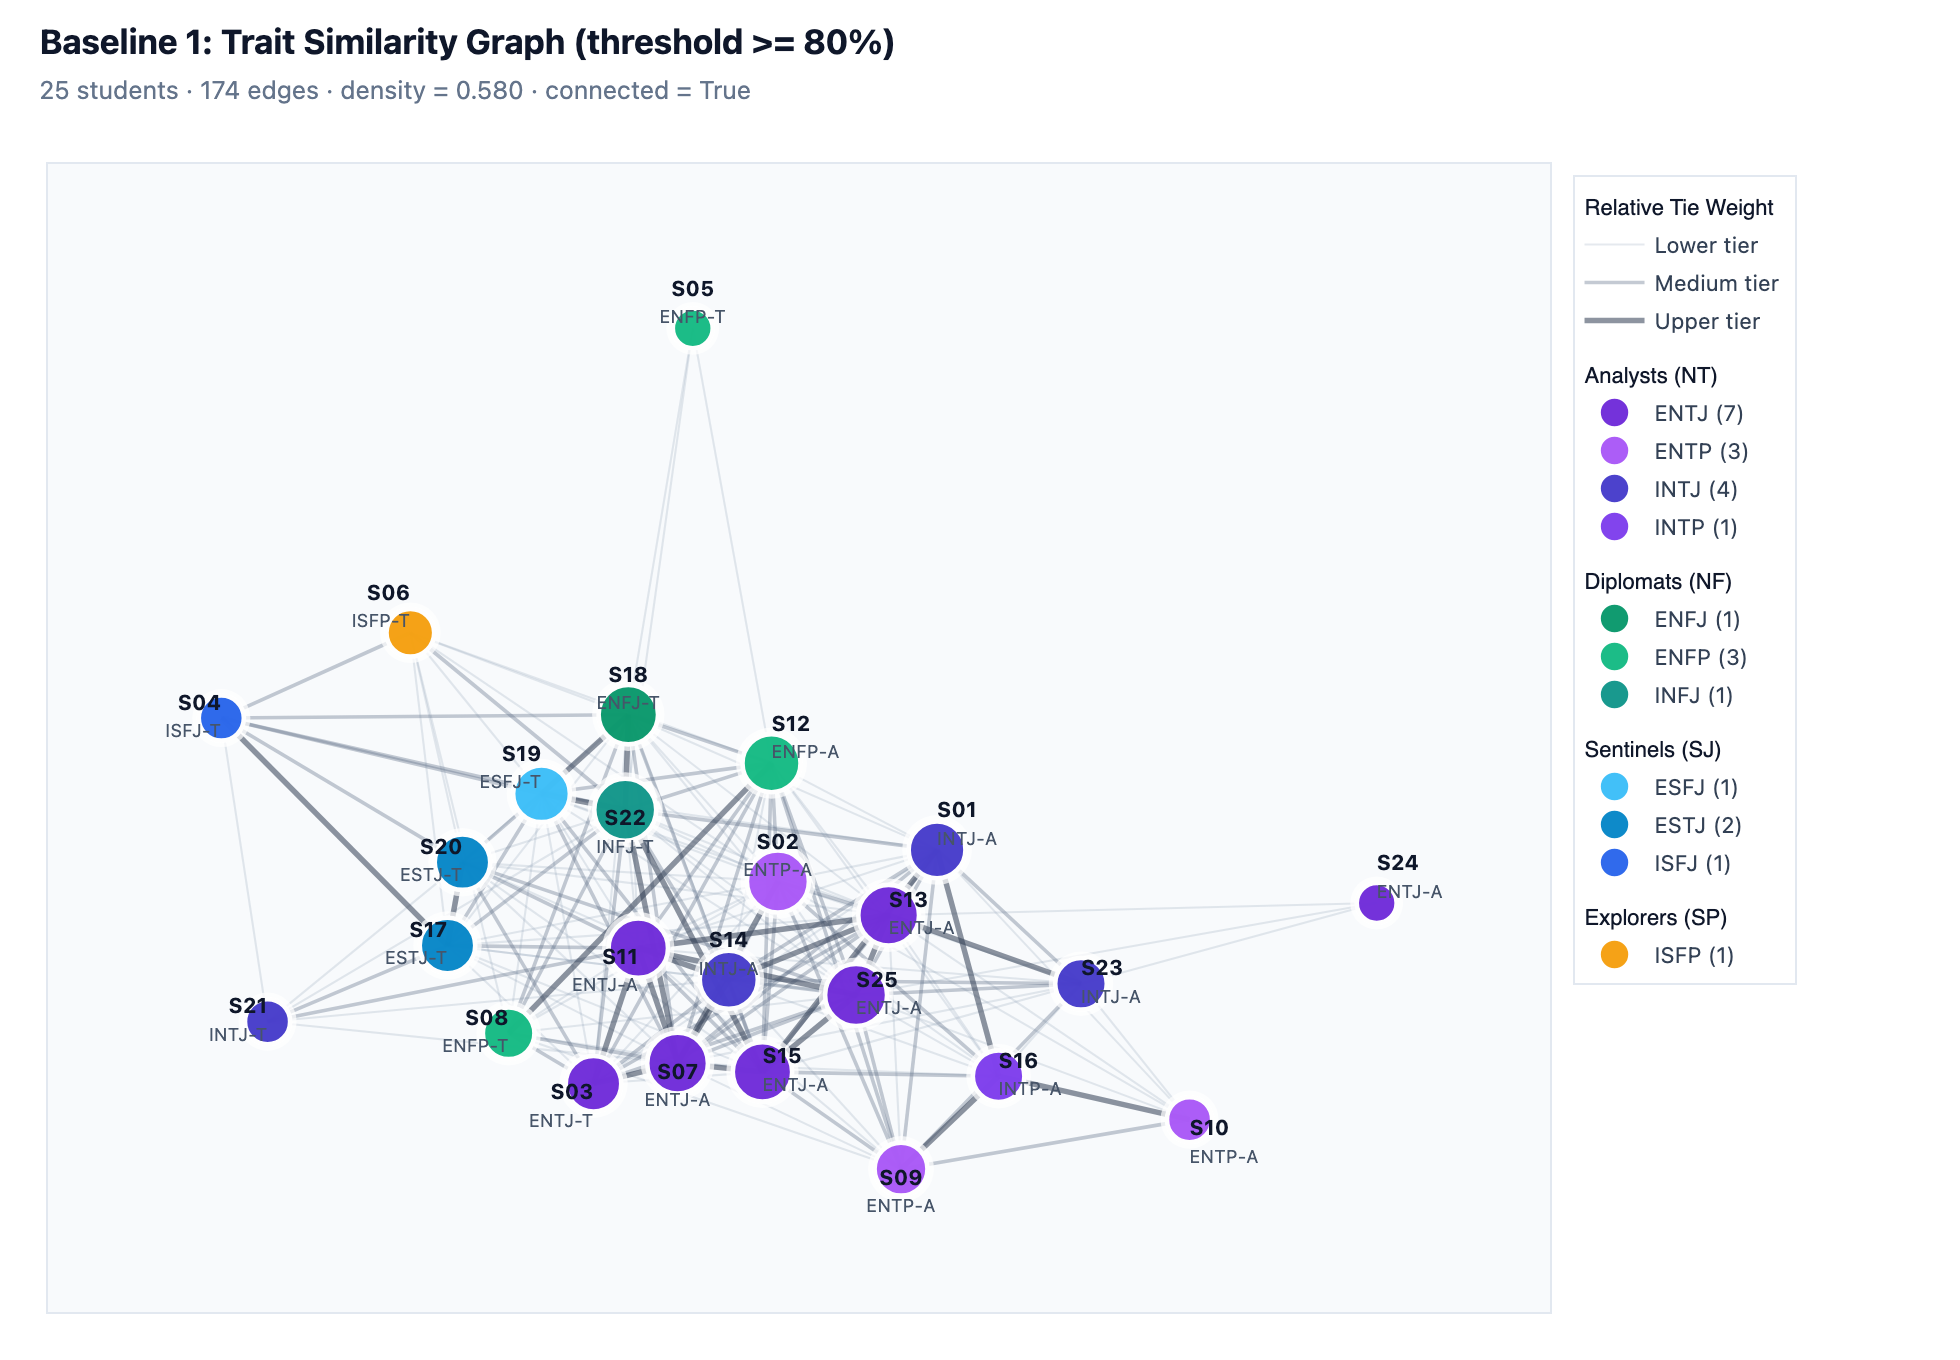

In [2]:
G_sim = G_base.copy()
students = df.index.tolist()
threshold = 0.80
sim_pairs = []

for i in range(len(students)):
    for j in range(i + 1, len(students)):
        u, v = students[i], students[j]
        diff = np.abs(df.loc[u, traits].values - df.loc[v, traits].values)
        sim = float(1.0 - diff.mean())
        if sim >= threshold:
            G_sim.add_edge(u, v, weight=sim)
            sim_pairs.append({
                "Student A": u, "MBTI A": df.loc[u, "mbti"],
                "Student B": v, "MBTI B": df.loc[v, "mbti"],
                "Similarity (%)": round(sim * 100, 1),
            })

sim_df = pd.DataFrame(sim_pairs).sort_values("Similarity (%)", ascending=False).reset_index(drop=True)
print(f"Similarity graph: {G_sim.number_of_nodes()} nodes, {G_sim.number_of_edges()} edges (density = {nx.density(G_sim):.2f})")
display(sim_df.head(10))

pos_sim = nx.spring_layout(G_sim, seed=42, k=1.25, iterations=200, weight="weight")
plot_network(G_sim, pos_sim, "Baseline 1: Trait Similarity Graph (threshold >= 80%)")

## 2. Baseline 2: Trait Contrast Graph

Next, we test the opposite intuition by measuring how strongly two students sit on opposite sides of the $50\%$ midpoint across the five traits, keeping each student's top $5$ contrasting links ($97$ edges). As expected, extreme profiles act as hubs pulling opposite poles together.

Contrast graph: 25 nodes, 97 edges


,Student A,MBTI A,Student B,MBTI B,Contrast (%)
0,S05,ENFP,S24,ENTJ,24.8
1,S05,ENFP,S23,INTJ,23.0
2,S05,ENFP,S10,ENTP,21.0
3,S06,ISFP,S24,ENTJ,19.8
4,S21,INTJ,S24,ENTJ,15.9
5,S05,ENFP,S09,ENTP,15.6
6,S04,ISFJ,S24,ENTJ,15.4
7,S04,ISFJ,S10,ENTP,15.2
8,S01,INTJ,S05,ENFP,14.7
9,S05,ENFP,S16,INTP,14.4


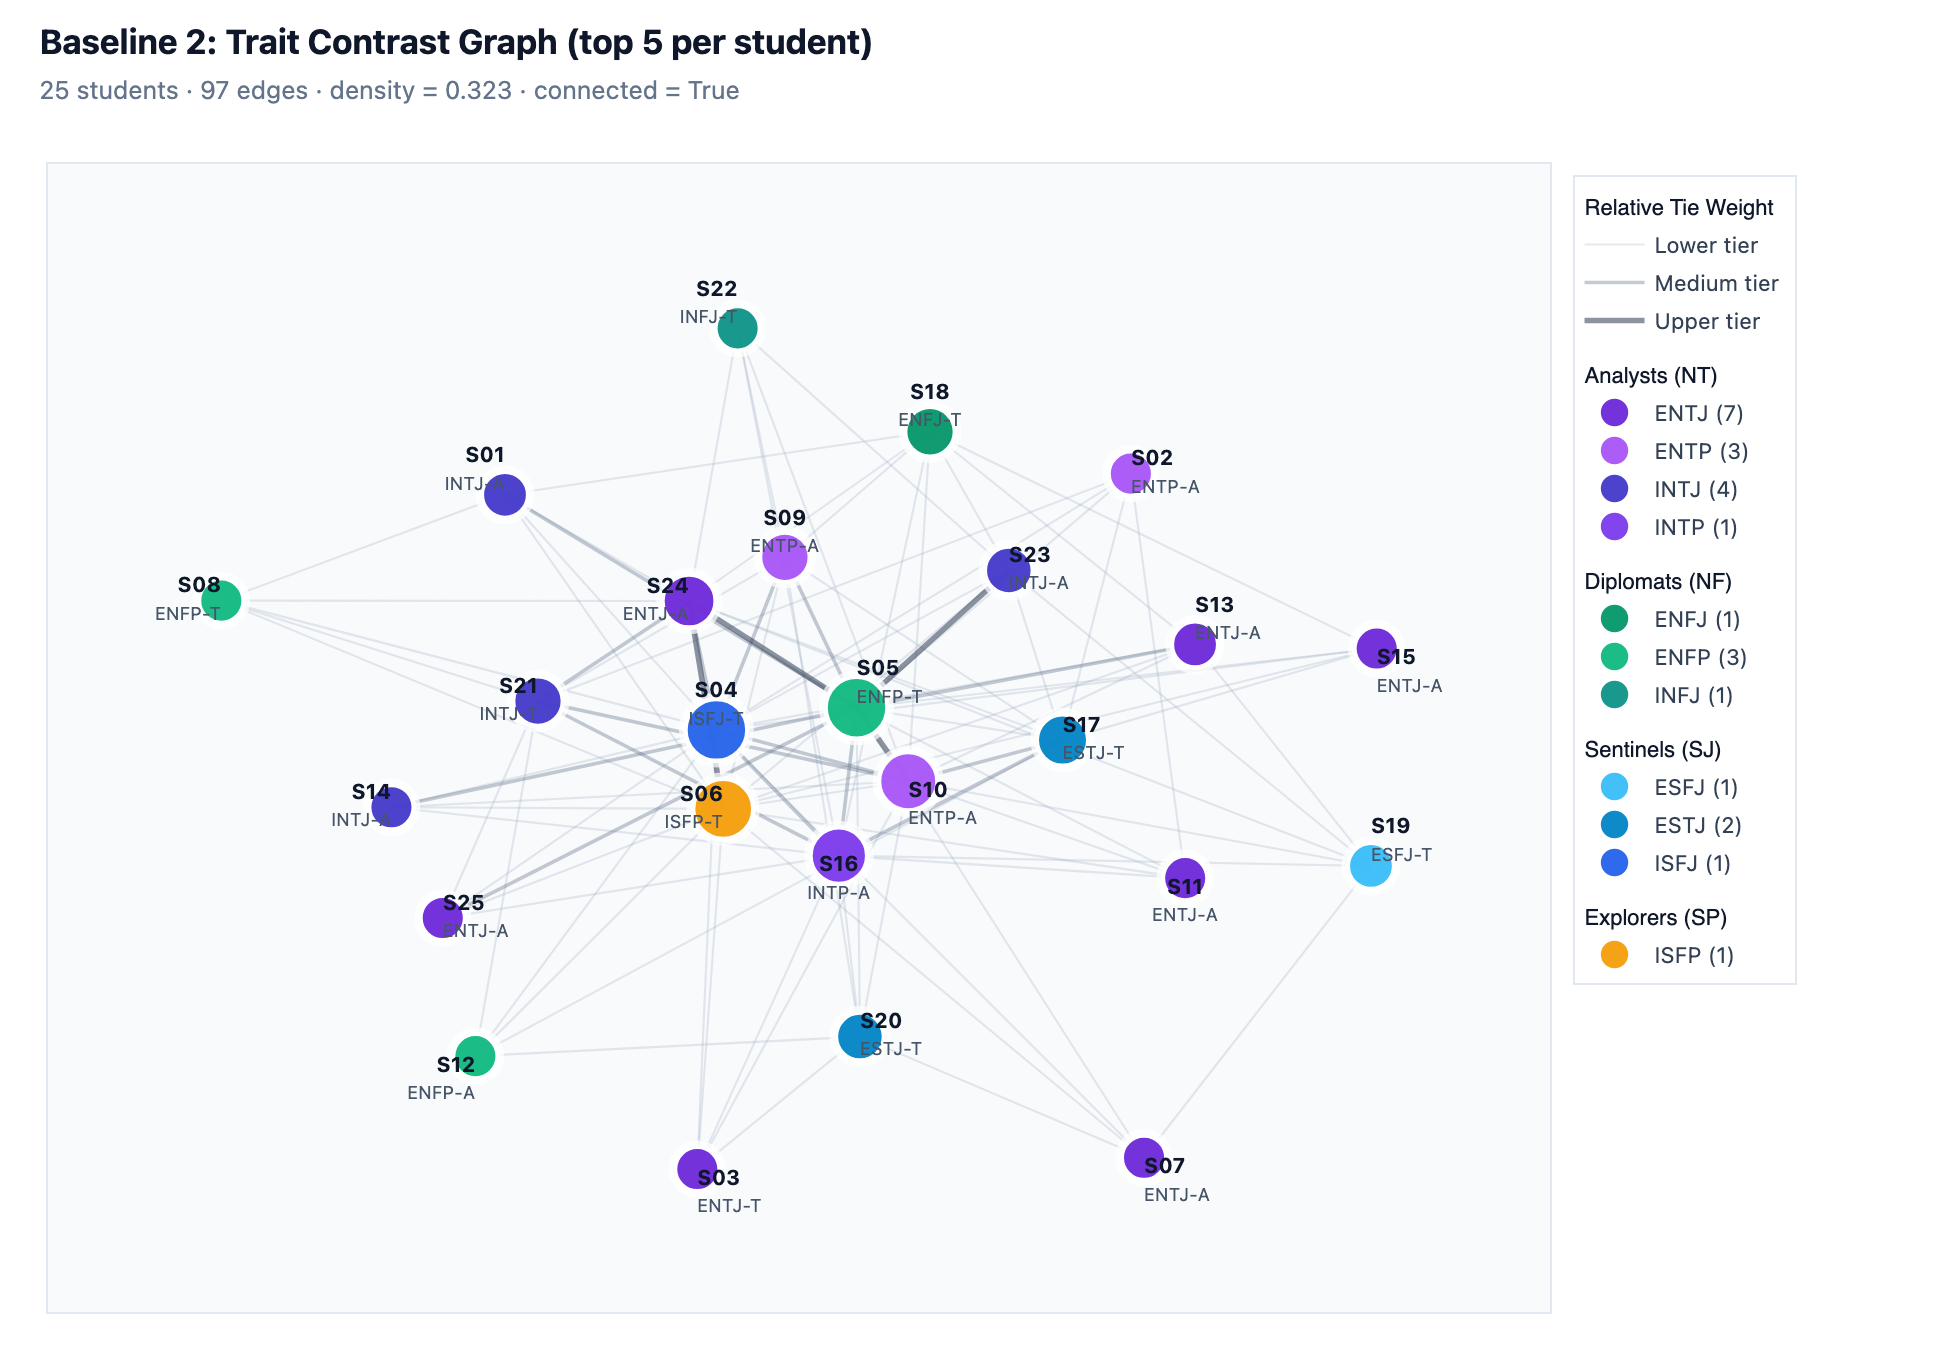

In [3]:
G_contrast = G_base.copy()
top_k = 5
centered = df[traits].values - 0.5
contrast_scores = {}

for i in range(len(students)):
    for j in range(i + 1, len(students)):
        opposition = 4.0 * np.maximum(0.0, -(centered[i] * centered[j]))
        contrast_scores[(i, j)] = float(opposition.mean())

for i, u in enumerate(students):
    neighbors = [
        (students[j], contrast_scores[(min(i, j), max(i, j))])
        for j in range(len(students)) if i != j
    ]
    neighbors.sort(key=lambda x: x[1], reverse=True)
    for v, score in neighbors[:top_k]:
        G_contrast.add_edge(u, v, weight=score)

contrast_df = pd.DataFrame([
    {
        "Student A": u, "MBTI A": df.loc[u, "mbti"],
        "Student B": v, "MBTI B": df.loc[v, "mbti"],
        "Contrast (%)": round(d["weight"] * 100, 1),
    }
    for u, v, d in G_contrast.edges(data=True)
]).sort_values("Contrast (%)", ascending=False).reset_index(drop=True)

print(f"Contrast graph: {G_contrast.number_of_nodes()} nodes, {G_contrast.number_of_edges()} edges")
display(contrast_df.head(10))

pos_con = nx.spring_layout(G_contrast, seed=42, k=1.05, iterations=200)
plot_network(G_contrast, pos_con, f"Baseline 2: Trait Contrast Graph (top {top_k} per student)")

## 3. Work-Group Compatibility Graph

To capture realistic project teamwork, we map each student $x_u$ to an ideal partner $x_u^*$:
- **Complementary** on `Energy` ($1 - E$) to balance outspoken and quieter teammates.
- **Aligned** on `Mind` ($N$) and `Nature` ($T$) for shared abstraction and feedback styles.
- **Anchored toward $0.65$** on `Tactics` ($J$) and `Identity` ($A$) for steady organization under deadlines.

We symmetrize the normalized Euclidean proximity into $w_{uv} \in [0, 1]$ and build an undirected **$4$-NN graph** ($25$ nodes, $73$ edges, density $= 0.24$).

Compatibility graph (4-NN): 25 nodes, 73 edges, density = 0.24, connected = True, degree range = [4, 11]


,Student A,Type A,Student B,Type B,Compatibility (%)
0,S01,INTJ-A,S25,ENTJ-A,94.4
1,S11,ENTJ-A,S14,INTJ-A,93.8
2,S13,ENTJ-A,S14,INTJ-A,93.8
3,S14,INTJ-A,S25,ENTJ-A,92.5
4,S18,ENFJ-T,S22,INFJ-T,92.2
5,S07,ENTJ-A,S14,INTJ-A,91.6
6,S01,INTJ-A,S09,ENTP-A,91.2
7,S17,ESTJ-T,S20,ESTJ-T,90.3
8,S01,INTJ-A,S15,ENTJ-A,90.1
9,S03,ENTJ-T,S14,INTJ-A,89.3


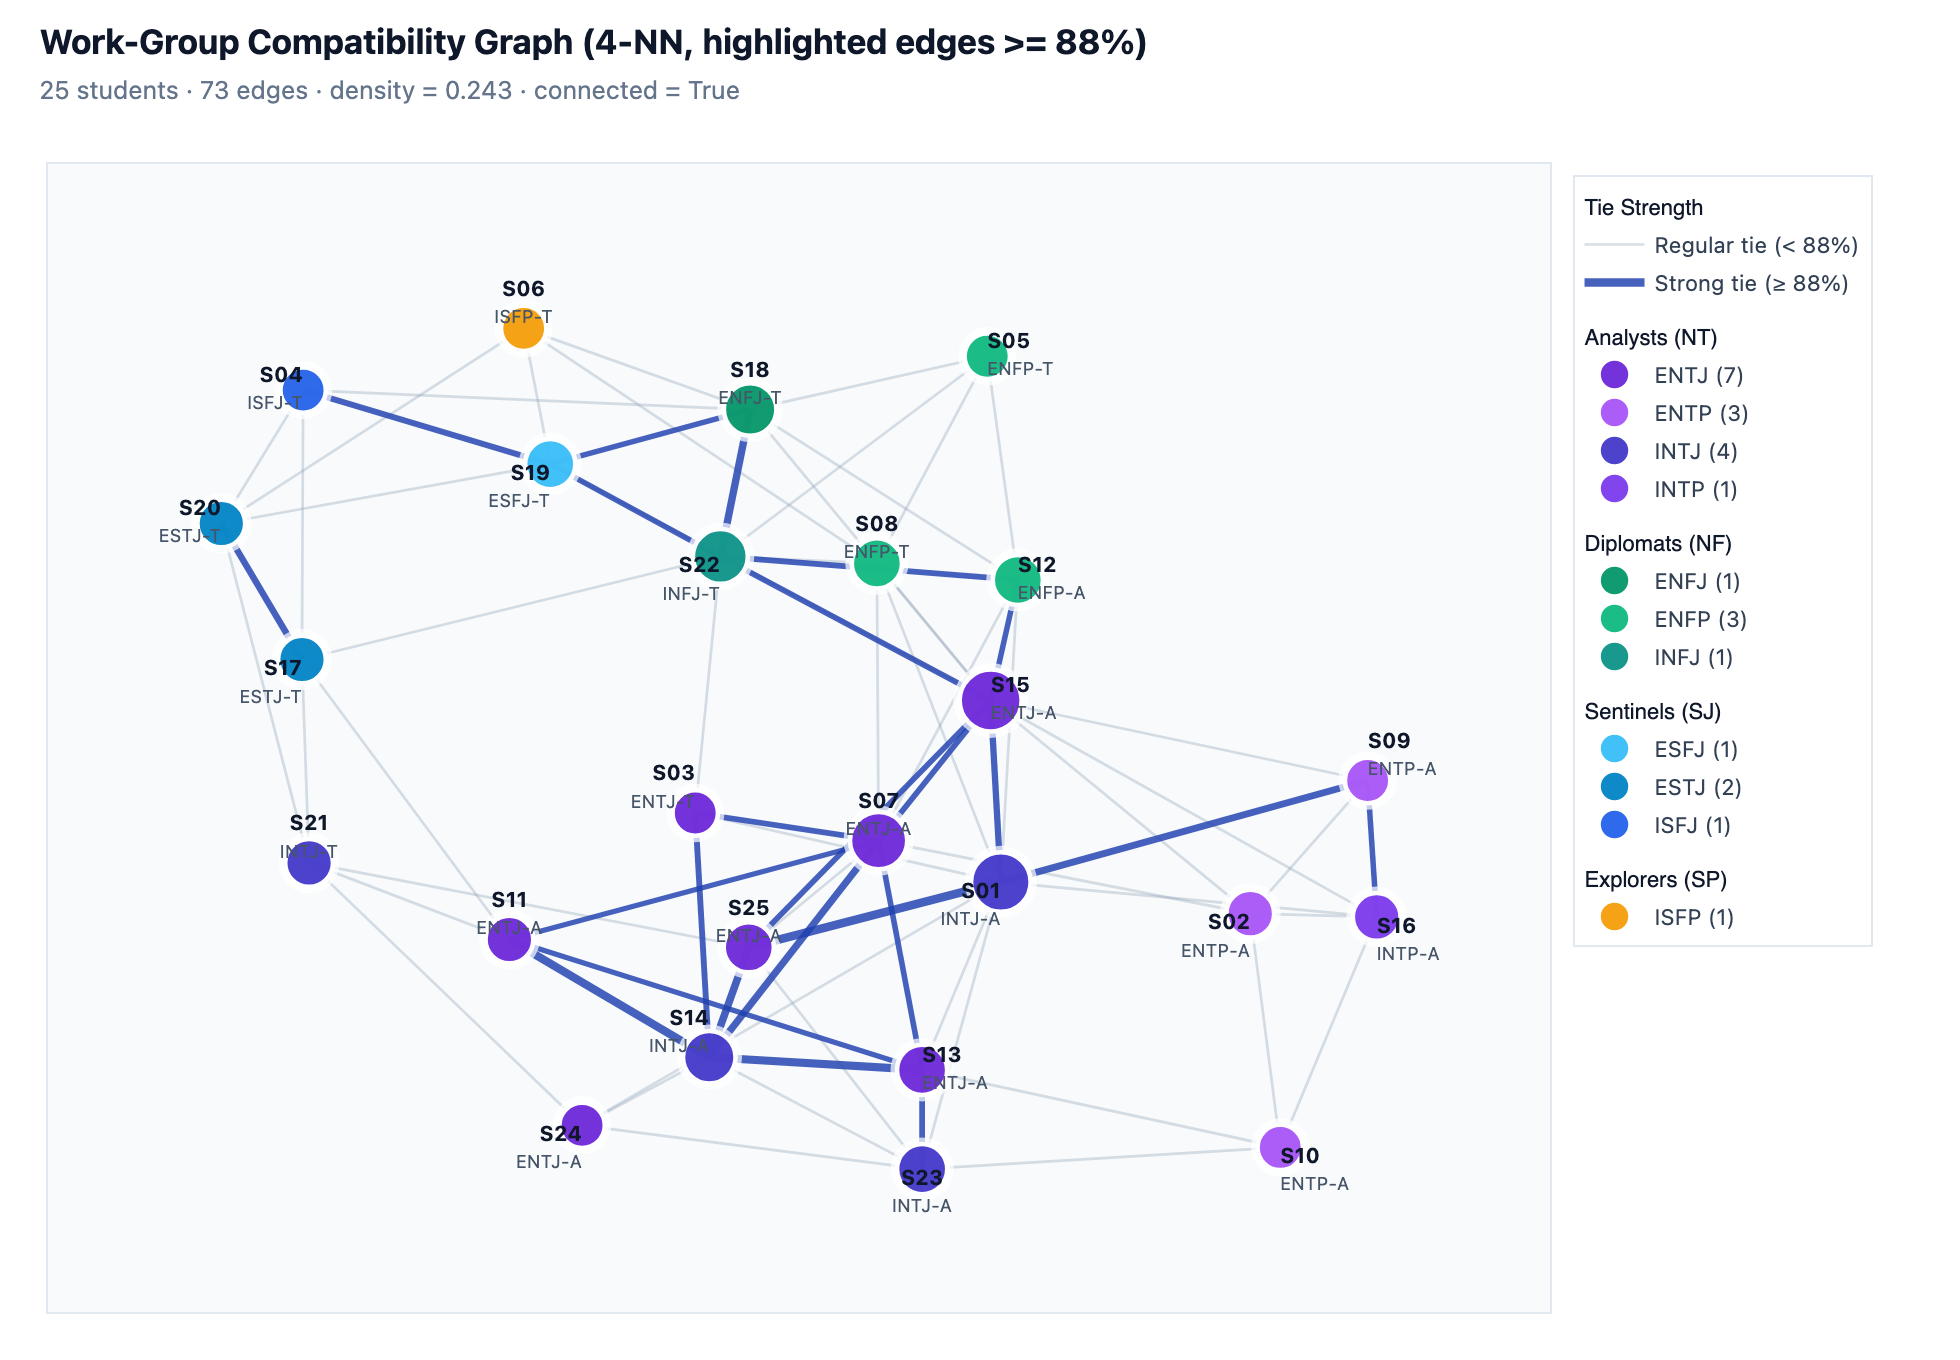

In [4]:
def ideal_partner(x, anchor=0.65):
    return np.array([
        1.0 - x[0],             # E: complementary energy
        x[1],                   # N: aligned intuition/sensing
        x[2],                   # T: aligned thinking/feeling
        0.5 * (x[3] + anchor),  # J: pulled toward structure
        0.5 * (x[4] + anchor),  # A: pulled toward calm stability
    ])


X = df[traits].values
X_ideal = np.array([ideal_partner(row) for row in X])
n = len(students)

compat_matrix = np.zeros((n, n))
compat_pairs = []

for i in range(n):
    for j in range(i + 1, n):
        u, v = students[i], students[j]
        d_ab = np.linalg.norm(X[j] - X_ideal[i]) / np.sqrt(len(traits))
        d_ba = np.linalg.norm(X[i] - X_ideal[j]) / np.sqrt(len(traits))
        score = float(1.0 - 0.5 * (d_ab + d_ba))

        compat_matrix[i, j] = compat_matrix[j, i] = score
        compat_pairs.append({
            "Student A": u, "Type A": f"{df.loc[u, 'mbti']}{df.loc[u, 'variant']}",
            "Student B": v, "Type B": f"{df.loc[v, 'mbti']}{df.loc[v, 'variant']}",
            "Compatibility (%)": round(score * 100, 1),
        })

G_compat = G_base.copy()
k_neighbors = 4
for i, u in enumerate(students):
    top_idx = [j for j in np.argsort(compat_matrix[i])[::-1] if j != i][:k_neighbors]
    for j in top_idx:
        G_compat.add_edge(u, students[j], weight=compat_matrix[i, j])

compat_df = pd.DataFrame(compat_pairs).sort_values("Compatibility (%)", ascending=False).reset_index(drop=True)
deg = dict(G_compat.degree())
print(
    f"Compatibility graph ({k_neighbors}-NN): {G_compat.number_of_nodes()} nodes, "
    f"{G_compat.number_of_edges()} edges, density = {nx.density(G_compat):.2f}, "
    f"connected = {nx.is_connected(G_compat)}, degree range = [{min(deg.values())}, {max(deg.values())}]"
)
display(compat_df.head(15))

pos_compat = nx.spring_layout(G_compat, seed=42, k=0.9, iterations=150, weight="weight")
plot_network(
    G_compat,
    pos_compat,
    f"Work-Group Compatibility Graph ({k_neighbors}-NN, highlighted edges >= 88%)",
    highlight_above=0.88,
)

## 4. Connectivity and Parameter Sensitivity

All three graphs are connected at their chosen settings, so we sweep each sparsity parameter to test robustness. `Trait similarity` fragments quickly above $0.80$, whereas `Work-group compatibility` reaches full $100\%$ connectivity from $k \ge 2$ onward, making $k = 4$ both sparse and safely connected. *(When a graph disconnects, inter-component distances become infinite, so distance metrics below are computed per connected component.)*

In [5]:
def connectivity_summary(G, model, setting):
    components = sorted(nx.connected_components(G), key=len, reverse=True)
    largest_size = len(components[0]) if components else 0
    node_count = G.number_of_nodes()
    return {
        "Model": model,
        "Setting": setting,
        "Nodes": node_count,
        "Edges": G.number_of_edges(),
        "Density": round(nx.density(G), 3),
        "Connected": len(components) == 1,
        "Components": len(components),
        "Largest component": largest_size,
        "Largest component (%)": round(100 * largest_size / node_count, 1) if node_count else 0.0,
        "Isolates": nx.number_of_isolates(G),
        "Component sizes": [len(component) for component in components],
    }


baseline_connectivity = pd.DataFrame([
    connectivity_summary(G_sim, "Trait similarity", f"threshold >= {threshold:.2f}"),
    connectivity_summary(G_contrast, "Trait contrast", f"top {top_k} per student"),
    connectivity_summary(G_compat, "Work-group compatibility", f"{k_neighbors}-NN"),
])
display(baseline_connectivity)

similarity_sweep = []
for cutoff in np.round(np.arange(0.60, 0.951, 0.05), 2):
    graph = G_base.copy()
    for i in range(len(students)):
        for j in range(i + 1, len(students)):
            similarity = float(1.0 - np.abs(df.loc[students[i], traits].values - df.loc[students[j], traits].values).mean())
            if similarity >= cutoff:
                graph.add_edge(students[i], students[j], weight=similarity)
    similarity_sweep.append(connectivity_summary(graph, "Trait similarity", f"threshold >= {cutoff:.2f}"))

contrast_sweep = []
compatibility_sweep = []
for k in range(1, len(students)):
    contrast_graph = G_base.copy()
    for i, student in enumerate(students):
        ranked = sorted(
            ((j, contrast_scores[(min(i, j), max(i, j))]) for j in range(len(students)) if j != i),
            key=lambda item: item[1],
            reverse=True,
        )
        for j, score in ranked[:k]:
            contrast_graph.add_edge(student, students[j], weight=score)
    contrast_sweep.append(connectivity_summary(contrast_graph, "Trait contrast", f"top {k} per student"))

    compatibility_graph = G_base.copy()
    for i, student in enumerate(students):
        ranked = sorted(
            (j for j in range(len(students)) if j != i),
            key=lambda j: compat_matrix[i, j],
            reverse=True,
        )
        for j in ranked[:k]:
            compatibility_graph.add_edge(student, students[j], weight=compat_matrix[i, j])
    compatibility_sweep.append(connectivity_summary(compatibility_graph, "Work-group compatibility", f"{k}-NN"))

sweep_columns = ["Setting", "Edges", "Density", "Connected", "Components", "Largest component", "Largest component (%)", "Isolates"]
display(pd.DataFrame(similarity_sweep)[sweep_columns])
display(pd.DataFrame(contrast_sweep)[sweep_columns])
display(pd.DataFrame(compatibility_sweep)[sweep_columns])

,Model,Setting,Nodes,Edges,Density,Connected,Components,Largest component,Largest component (%),Isolates,Component sizes
0,Trait similarity,threshold >= 0.80,25,174,0.580,True,1,25,100.0,0,[25]
1,Trait contrast,top 5 per student,25,97,0.323,True,1,25,100.0,0,[25]
2,Work-group compatibility,4-NN,25,73,0.243,True,1,25,100.0,0,[25]


,Setting,Edges,Density,Connected,Components,Largest component,Largest component (%),Isolates
0,threshold >= 0.60,296,0.987,True,1,25,100.0,0
1,threshold >= 0.65,288,0.960,True,1,25,100.0,0
2,threshold >= 0.70,267,0.890,True,1,25,100.0,0
3,threshold >= 0.75,238,0.793,True,1,25,100.0,0
4,threshold >= 0.80,174,0.580,True,1,25,100.0,0
5,threshold >= 0.85,87,0.290,False,3,23,92.0,2
6,threshold >= 0.90,25,0.083,False,7,16,64.0,4
7,threshold >= 0.95,0,0.000,False,25,1,4.0,25


,Setting,Edges,Density,Connected,Components,Largest component,Largest component (%),Isolates
0,top 1 per student,24,0.080,True,1,25,100.0,0
1,top 2 per student,45,0.150,True,1,25,100.0,0
2,top 3 per student,65,0.217,True,1,25,100.0,0
3,top 4 per student,82,0.273,True,1,25,100.0,0
4,top 5 per student,97,0.323,True,1,25,100.0,0
5,top 6 per student,113,0.377,True,1,25,100.0,0
6,top 7 per student,125,0.417,True,1,25,100.0,0
7,top 8 per student,138,0.460,True,1,25,100.0,0
8,top 9 per student,149,0.497,True,1,25,100.0,0
9,top 10 per student,163,0.543,True,1,25,100.0,0


,Setting,Edges,Density,Connected,Components,Largest component,Largest component (%),Isolates
0,1-NN,20,0.067,False,5,8,32.0,0
1,2-NN,38,0.127,True,1,25,100.0,0
2,3-NN,56,0.187,True,1,25,100.0,0
3,4-NN,73,0.243,True,1,25,100.0,0
4,5-NN,91,0.303,True,1,25,100.0,0
5,6-NN,105,0.350,True,1,25,100.0,0
6,7-NN,120,0.400,True,1,25,100.0,0
7,8-NN,136,0.453,True,1,25,100.0,0
8,9-NN,153,0.510,True,1,25,100.0,0
9,10-NN,165,0.550,True,1,25,100.0,0


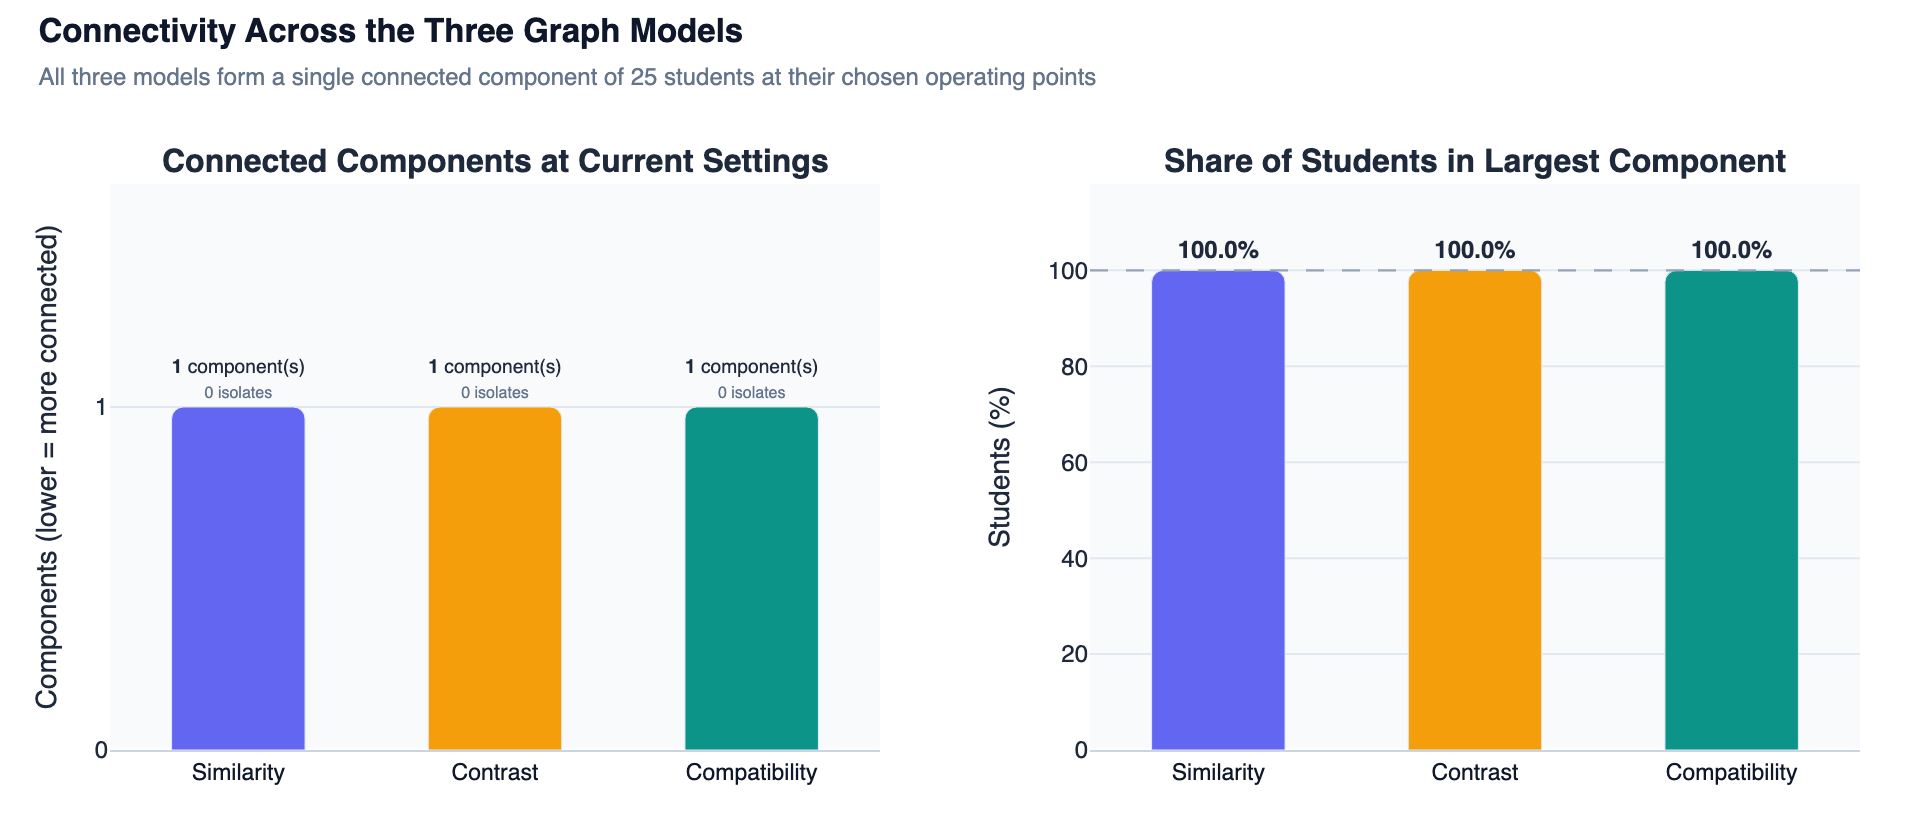

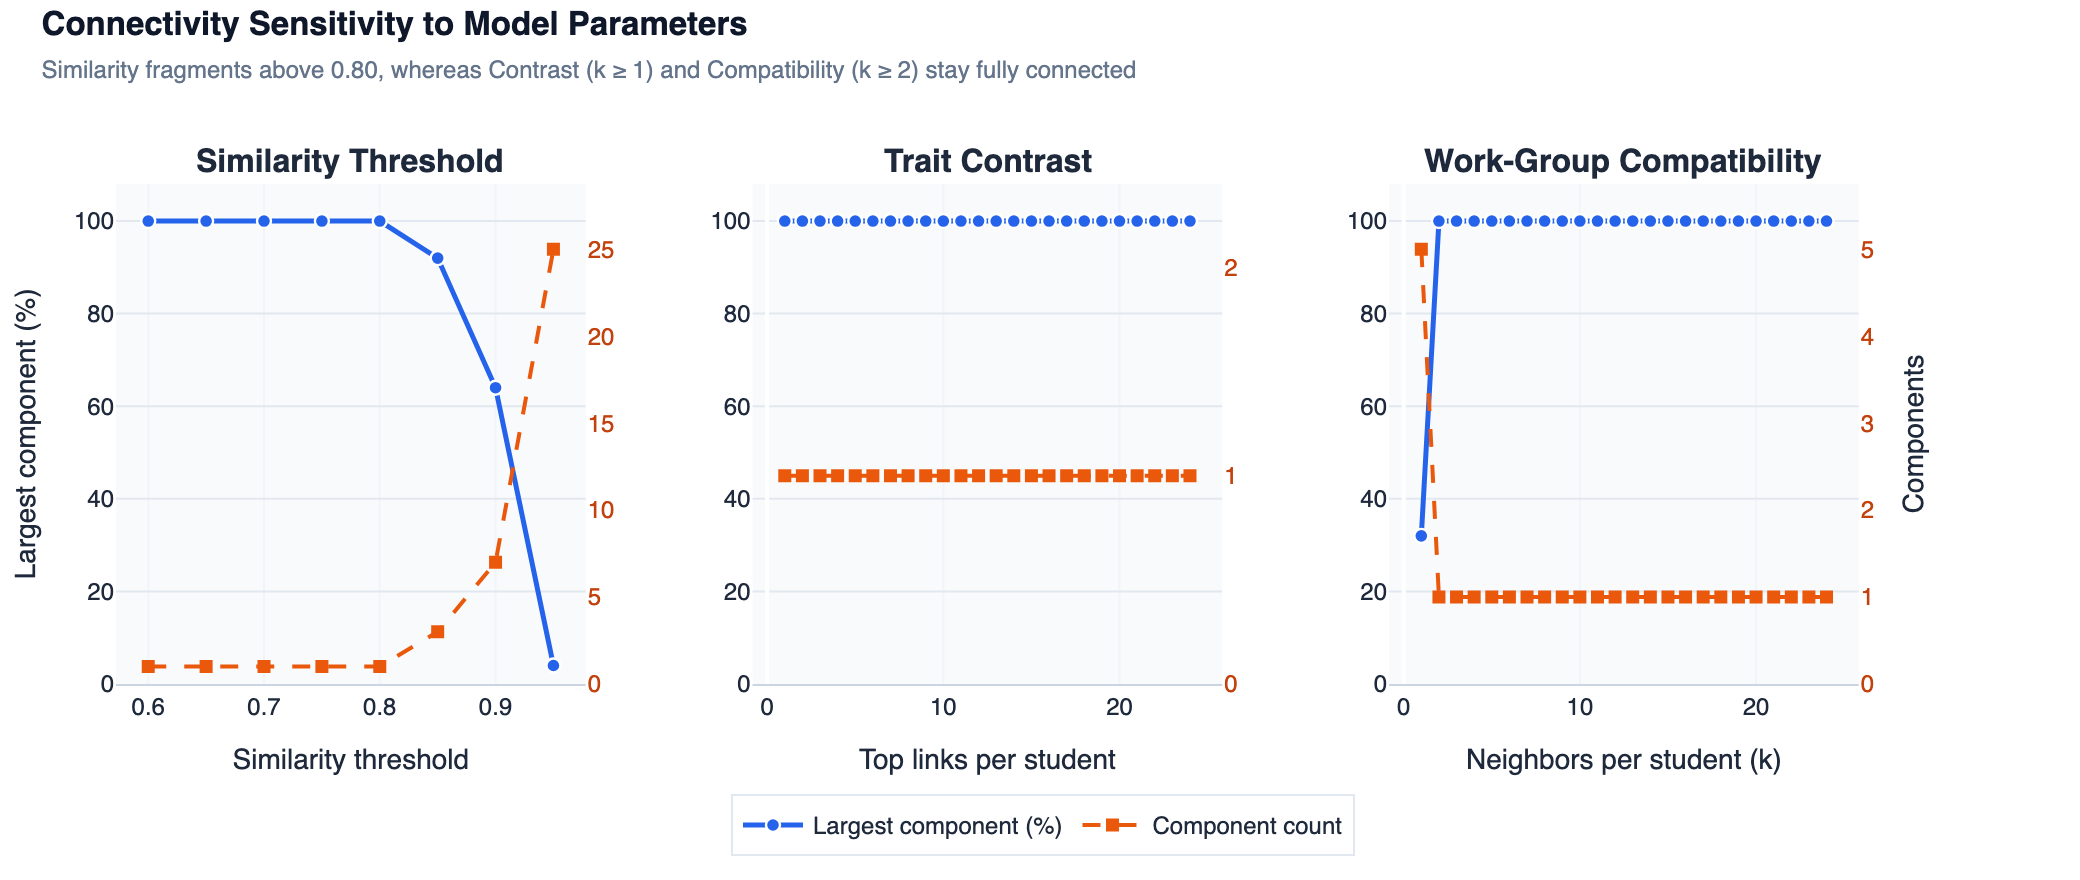

In [6]:
model_order = ["Trait similarity", "Trait contrast", "Work-group compatibility"]
model_short = ["Similarity", "Contrast", "Compatibility"]
model_colors = ["#6366F1", "#F59E0B", "#0D9488"]

# Compare the current graph settings by component structure and reachable share.
baseline_plot = (
    baseline_connectivity.set_index("Model").reindex(model_order)
)

fig_conn_bar = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=("<b>Connected Components at Current Settings</b>", "<b>Share of Students in Largest Component</b>"),
    horizontal_spacing=0.12,
)
fig_conn_bar.add_trace(
    go.Bar(
        x=model_short,
        y=baseline_plot["Components"],
        marker=dict(color=model_colors, cornerradius=6),
        width=0.52,
        text=[
            f"<b>{int(r['Components'])}</b> component(s)<br><span style='font-size:10px;color:#64748B'>{int(r['Isolates'])} isolates</span>"
            for _, r in baseline_plot.iterrows()
        ],
        textposition="outside",
        showlegend=False,
    ),
    row=1,
    col=1,
)
fig_conn_bar.add_trace(
    go.Bar(
        x=model_short,
        y=baseline_plot["Largest component (%)"],
        marker=dict(color=model_colors, cornerradius=6),
        width=0.52,
        text=[f"<b>{v:.1f}%</b>" for v in baseline_plot["Largest component (%)"]],
        textposition="outside",
        showlegend=False,
    ),
    row=1,
    col=2,
)
fig_conn_bar.add_hline(y=100, line_dash="dash", line_color="#94A3B8", line_width=1.2, row=1, col=2)
fig_conn_bar.update_yaxes(
    title_text="Components (lower = more connected)",
    range=[0, max(1.65, float(baseline_plot["Components"].max()) * 1.45)],
    dtick=1,
    gridcolor="#E2E8F0",
    row=1,
    col=1,
)
fig_conn_bar.update_yaxes(title_text="Students (%)", range=[0, 118], gridcolor="#E2E8F0", row=1, col=2)
fig_conn_bar.update_xaxes(linecolor="#CBD5E1", tickfont=dict(size=11.5, color="#0F172A"))
fig_conn_bar.update_layout(
    title=dict(
        text="<b>Connectivity Across the Three Graph Models</b><br><span style='font-size:12px;color:#64748B;font-weight:400'>All three models form a single connected component of 25 students at their chosen operating points</span>",
        x=0.02,
        y=0.95,
        font=dict(size=16.5, color="#0F172A", family="Inter, -apple-system, sans-serif"),
    ),
    width=960,
    height=420,
    paper_bgcolor="#FFFFFF",
    plot_bgcolor="#F8FAFC",
    font=dict(family="Inter, -apple-system, sans-serif", color="#1E293B"),
    margin=dict(l=55, r=30, t=92, b=45),
)
fig_conn_bar.show()

# Show how the largest component and total component count change as each model is tuned.
sweep_specs = [
    (similarity_sweep, "Similarity threshold", 5),
    (contrast_sweep, "Top links per student", 1),
    (compatibility_sweep, "Neighbors per student (k)", 1),
]
fig_sweep = make_subplots(
    rows=1,
    cols=3,
    specs=[[{"secondary_y": True}, {"secondary_y": True}, {"secondary_y": True}]],
    subplot_titles=("<b>Similarity Threshold</b>", "<b>Trait Contrast</b>", "<b>Work-Group Compatibility</b>"),
    horizontal_spacing=0.09,
)
for col_idx, (sweep, x_label, comp_dtick) in enumerate(sweep_specs, start=1):
    sweep_plot = pd.DataFrame(sweep).copy()
    sweep_plot["Parameter"] = sweep_plot["Setting"].str.extract(r"([0-9]+(?:\.[0-9]+)?)").astype(float)
    sweep_plot = sweep_plot.sort_values("Parameter")
    max_comp = float(sweep_plot["Components"].max())

    fig_sweep.add_trace(
        go.Scatter(
            x=sweep_plot["Parameter"],
            y=sweep_plot["Largest component (%)"],
            mode="lines+markers",
            name="Largest component (%)",
            line=dict(color="#2563EB", width=2.5),
            marker=dict(size=7, color="#2563EB", line=dict(width=1.2, color="#FFFFFF")),
            showlegend=(col_idx == 1),
        ),
        row=1,
        col=col_idx,
        secondary_y=False,
    )
    fig_sweep.add_trace(
        go.Scatter(
            x=sweep_plot["Parameter"],
            y=sweep_plot["Components"],
            mode="lines+markers",
            name="Component count",
            line=dict(color="#EA580C", width=2.0, dash="dash"),
            marker=dict(size=6.5, symbol="square", color="#EA580C"),
            showlegend=(col_idx == 1),
        ),
        row=1,
        col=col_idx,
        secondary_y=True,
    )
    fig_sweep.update_xaxes(title_text=x_label, gridcolor="#F1F5F9", linecolor="#CBD5E1", row=1, col=col_idx)
    fig_sweep.update_yaxes(
        title_text="Largest component (%)" if col_idx == 1 else "",
        range=[0, 108],
        gridcolor="#E2E8F0",
        secondary_y=False,
        row=1,
        col=col_idx,
    )
    fig_sweep.update_yaxes(
        title_text="Components" if col_idx == 3 else "",
        range=[0, max(2.4, max_comp * 1.15)],
        dtick=comp_dtick,
        tickfont=dict(color="#C2410C"),
        showgrid=False,
        secondary_y=True,
        row=1,
        col=col_idx,
    )

fig_sweep.update_layout(
    title=dict(
        text="<b>Connectivity Sensitivity to Model Parameters</b><br><span style='font-size:12px;color:#64748B;font-weight:400'>Similarity fragments above 0.80, whereas Contrast (k ≥ 1) and Compatibility (k ≥ 2) stay fully connected</span>",
        x=0.02,
        y=0.96,
        font=dict(size=16.5, color="#0F172A", family="Inter, -apple-system, sans-serif"),
    ),
    width=1040,
    height=440,
    paper_bgcolor="#FFFFFF",
    plot_bgcolor="#F8FAFC",
    font=dict(family="Inter, -apple-system, sans-serif", color="#1E293B"),
    legend=dict(orientation="h", x=0.5, y=-0.22, xanchor="center", bgcolor="rgba(255,255,255,0.92)", bordercolor="#E2E8F0", borderwidth=1),
    margin=dict(l=55, r=55, t=92, b=82),
)
fig_sweep.show()

## 5. Distance Measures

We compute **diameter** and **radius** per connected component under two conventions: unweighted hop count and weighted shortest-path cost ($d_{uv} = 1 - w_{uv}$ via Dijkstra, so stronger compatibility means shorter distance).

On `G_compat`, the cohort stays compact with a hop diameter of $4$ and radius of $2$ (center: `S15`), and a weighted diameter of $0.619$ and radius of $0.312$ (center: `S15`; periphery: `S05` and `S10`).

In [7]:
def distance_metrics_by_component(G, model):
    components = sorted(nx.connected_components(G), key=len, reverse=True)
    rows = []

    for component_number, nodes in enumerate(components, start=1):
        component = G.subgraph(nodes).copy()
        weighted_component = component.copy()

        for _, _, attrs in weighted_component.edges(data=True):
            if "weight" not in attrs:
                raise ValueError(f"{model} has an edge without a strength weight")
            strength = float(attrs["weight"])
            if not np.isfinite(strength) or not 0.0 <= strength <= 1.0:
                raise ValueError(f"{model} edge strengths must be finite values in [0, 1]")
            attrs["distance"] = 1.0 - strength

        weighted_shortest_paths = dict(
            nx.all_pairs_dijkstra_path_length(weighted_component, weight="distance")
        )
        weighted_eccentricities = {
            node: max(distances.values())
            for node, distances in weighted_shortest_paths.items()
        }

        rows.append({
            "Model": model,
            "Graph connected": len(components) == 1,
            "Component": component_number,
            "Component nodes": component.number_of_nodes(),
            "Component edges": component.number_of_edges(),
            "Diameter (hops)": nx.diameter(component),
            "Radius (hops)": nx.radius(component),
            "Weighted diameter (sum of 1 - w)": round(max(weighted_eccentricities.values()), 3),
            "Weighted radius (sum of 1 - w)": round(min(weighted_eccentricities.values()), 3),
        })

    return rows


distance_results = pd.DataFrame([
    row
    for model, graph in [
        ("Trait similarity", G_sim),
        ("Trait contrast", G_contrast),
        ("Work-group compatibility", G_compat),
    ]
    for row in distance_metrics_by_component(graph, model)
])
display(distance_results)

,Model,Graph connected,Component,Component nodes,Component edges,Diameter (hops),Radius (hops),Weighted diameter (sum of 1 - w),Weighted radius (sum of 1 - w)
0,Trait similarity,True,1,25,174,3,2,0.522,0.278
1,Trait contrast,True,1,25,97,3,2,2.705,1.746
2,Work-group compatibility,True,1,25,73,4,2,0.619,0.312


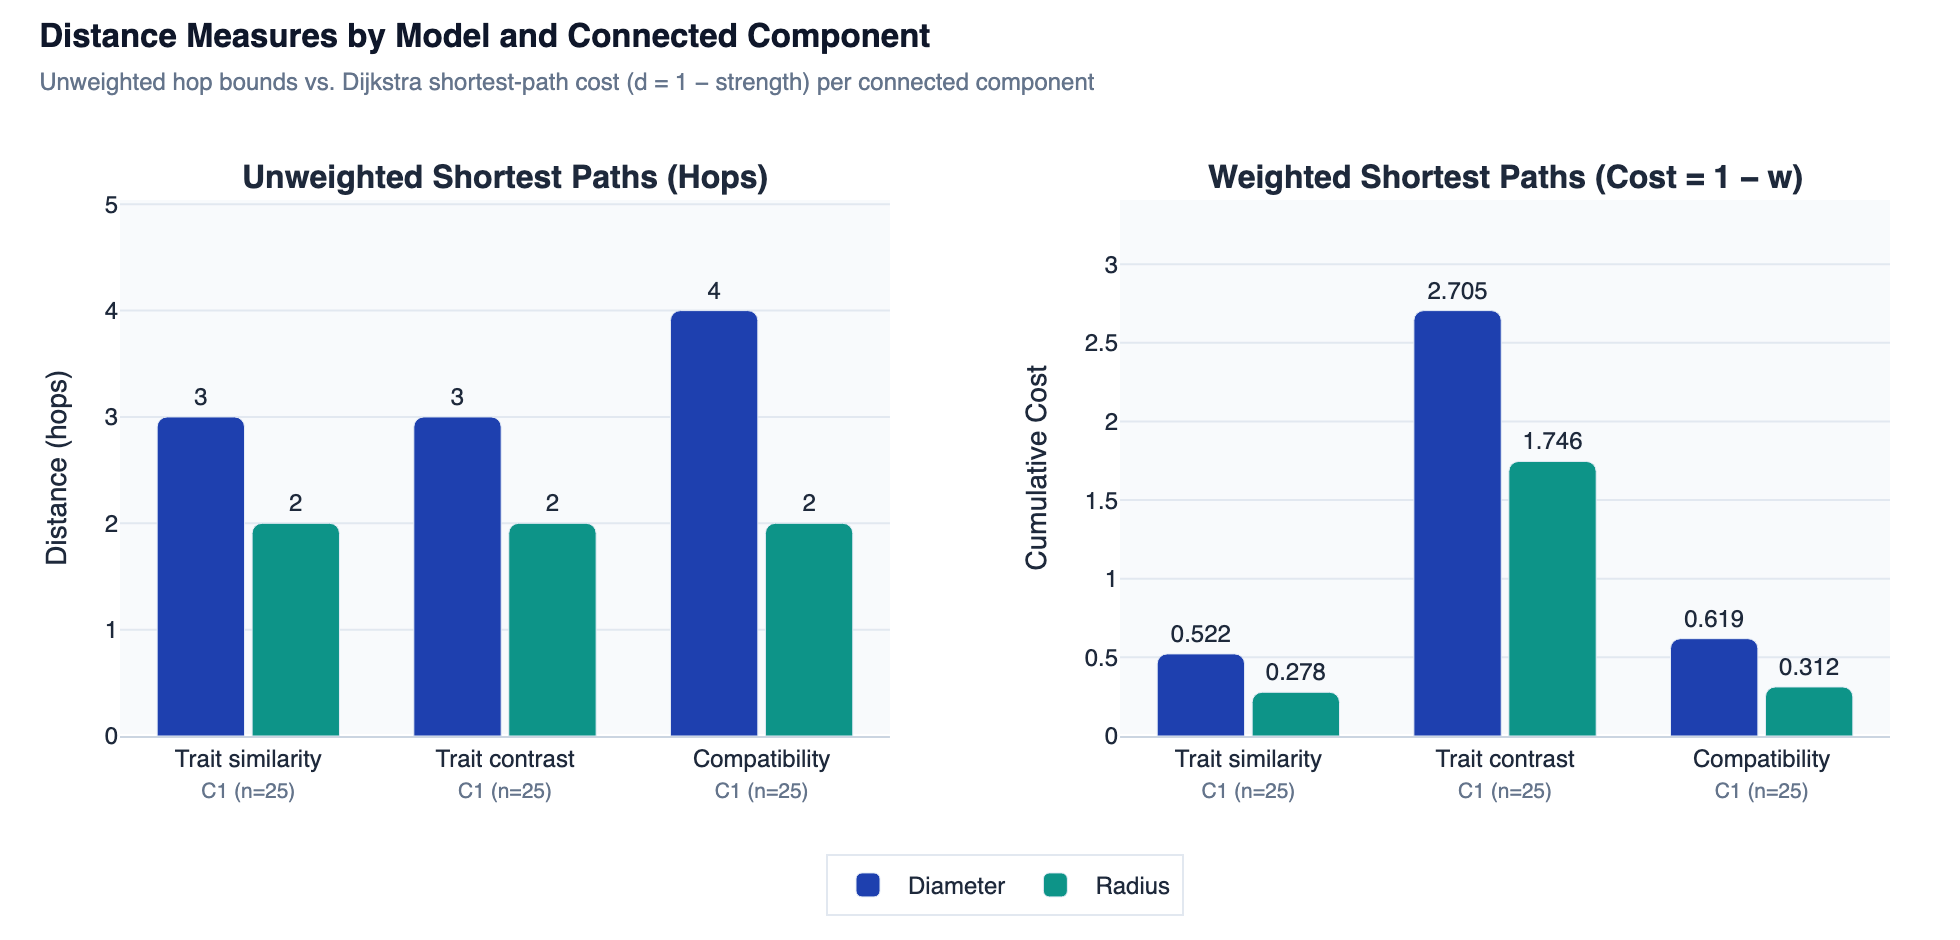

In [8]:
# Compare hop distances and strength-derived costs for every connected component.
distance_plot = distance_results.copy()
distance_plot["Component label"] = distance_plot.apply(
    lambda row: (
        f"{row['Model'].replace('Work-group ', '').capitalize()}"
        f"<br><span style='font-size:10.5px;color:#64748B'>C{int(row['Component'])} (n={int(row['Component nodes'])})</span>"
    ),
    axis=1,
)

fig_dist = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=("<b>Unweighted Shortest Paths (Hops)</b>", "<b>Weighted Shortest Paths (Cost = 1 − w)</b>"),
    horizontal_spacing=0.13,
)
for col_idx, (d_col, r_col, fmt) in enumerate(
    [
        ("Diameter (hops)", "Radius (hops)", "{:.0f}"),
        ("Weighted diameter (sum of 1 - w)", "Weighted radius (sum of 1 - w)", "{:.3f}"),
    ],
    start=1,
):
    fig_dist.add_trace(
        go.Bar(
            x=distance_plot["Component label"],
            y=distance_plot[d_col],
            name="Diameter",
            marker=dict(color="#1E40AF", cornerradius=5),
            text=[fmt.format(v) for v in distance_plot[d_col]],
            textposition="outside",
            showlegend=(col_idx == 1),
        ),
        row=1,
        col=col_idx,
    )
    fig_dist.add_trace(
        go.Bar(
            x=distance_plot["Component label"],
            y=distance_plot[r_col],
            name="Radius",
            marker=dict(color="#0D9488", cornerradius=5),
            text=[fmt.format(v) for v in distance_plot[r_col]],
            textposition="outside",
            showlegend=(col_idx == 1),
        ),
        row=1,
        col=col_idx,
    )
    fig_dist.update_yaxes(
        title_text="Distance (hops)" if col_idx == 1 else "Cumulative Cost",
        range=[0, float(distance_plot[d_col].max()) * 1.26],
        gridcolor="#E2E8F0",
        row=1,
        col=col_idx,
    )
    fig_dist.update_xaxes(
        tickangle=0,
        linecolor="#CBD5E1",
        row=1,
        col=col_idx,
    )

fig_dist.update_layout(
    barmode="group",
    bargap=0.26,
    bargroupgap=0.08,
    title=dict(
        text="<b>Distance Measures by Model and Connected Component</b><br><span style='font-size:12px;color:#64748B;font-weight:400'>Unweighted hop bounds vs. Dijkstra shortest-path cost (d = 1 − strength) per connected component</span>",
        x=0.02,
        y=0.95,
        font=dict(size=16.5, color="#0F172A", family="Inter, -apple-system, sans-serif"),
    ),
    width=980,
    height=470,
    paper_bgcolor="#FFFFFF",
    plot_bgcolor="#F8FAFC",
    font=dict(family="Inter, -apple-system, sans-serif", color="#1E293B"),
    legend=dict(
        orientation="h",
        x=0.5,
        xanchor="center",
        y=-0.22,
        yanchor="top",
        bgcolor="rgba(255,255,255,0.95)",
        bordercolor="#E2E8F0",
        borderwidth=1,
    ),
    margin=dict(l=60, r=35, t=100, b=95),
)
fig_dist.show()

## 6. Centrality Measures

We evaluate five complementary centralities across all models: **Degree**, **Strength** (sum of weights), **Betweenness** (unweighted and weighted with $d = 1 - w$), **Closeness**, and component-wise **Eigenvector** centrality.

On `G_compat`, the same four students (`S15`, `S01`, `S07`, `S22`) rank #1 to #4 in identical order across local, path-based, and spectral metrics, naturally bridging introverted and extraverted working styles.

In [9]:
graph_models = [
    ("Trait similarity", G_sim),
    ("Trait contrast", G_contrast),
    ("Work-group compatibility", G_compat),
]
centrality_rows = []
for model, graph in graph_models:
    G_dist = graph.copy()
    for _, _, attrs in G_dist.edges(data=True):
        attrs["distance"] = 1.0 - float(attrs["weight"])

    degree = dict(graph.degree())
    degree_centrality = nx.degree_centrality(graph)
    strength = dict(graph.degree(weight="weight"))
    betweenness = nx.betweenness_centrality(graph, normalized=True)
    betweenness_weighted = nx.betweenness_centrality(G_dist, weight="distance", normalized=True)
    closeness = nx.closeness_centrality(graph, wf_improved=True)

    eigenvector = {}
    component_numbers = {}
    components = sorted(nx.connected_components(graph), key=len, reverse=True)
    for component_number, nodes in enumerate(components, start=1):
        component_graph = graph.subgraph(nodes)
        component_numbers.update({node: component_number for node in nodes})
        if len(nodes) == 1:
            eigenvector.update({node: 1.0 for node in nodes})
        else:
            eigenvector.update(nx.eigenvector_centrality(component_graph, max_iter=1000, weight="weight"))

    for node in graph:
        centrality_rows.append({
            "Model": model,
            "Student": node,
            "MBTI": f"{df.loc[node, 'mbti']}{df.loc[node, 'variant']}",
            "Component": component_numbers[node],
            "Degree": degree[node],
            "Degree centrality": round(degree_centrality[node], 3),
            "Strength": round(strength[node], 3),
            "Betweenness": round(betweenness[node], 3),
            "Weighted betweenness (1-w)": round(betweenness_weighted[node], 3),
            "Closeness": round(closeness[node], 3),
            "Eigenvector": round(eigenvector[node], 3),
        })

centrality_results = pd.DataFrame(centrality_rows)
display(centrality_results.sort_values(["Model", "Betweenness"], ascending=[True, False]).reset_index(drop=True))

compatibility_centrality = centrality_results[
    centrality_results["Model"] == "Work-group compatibility"
]
top_centrality_rows = []
for measure in ["Degree", "Strength", "Betweenness", "Closeness", "Eigenvector"]:
    top_rows = compatibility_centrality.nlargest(5, measure)[["Student", "MBTI", measure]].rename(
        columns={measure: "Score"}
    )
    top_rows.insert(0, "Measure", measure)
    top_centrality_rows.append(top_rows)
top_compatibility_centrality = pd.concat(top_centrality_rows, ignore_index=True)
display(top_compatibility_centrality)

,Model,Student,MBTI,Component,Degree,Degree centrality,Strength,Betweenness,Weighted betweenness (1-w),Closeness,Eigenvector
0,Trait contrast,S04,ISFJ-T,1,15,0.625,1.119,0.124,0.004,0.727,0.272
1,Trait contrast,S05,ENFP-T,1,15,0.625,1.911,0.118,0.348,0.727,0.472
2,Trait contrast,S06,ISFP-T,1,14,0.583,1.139,0.112,0.112,0.706,0.255
3,Trait contrast,S10,ENTP-A,1,13,0.542,1.218,0.082,0.123,0.686,0.328
4,Trait contrast,S16,INTP-A,1,12,0.500,0.924,0.079,0.011,0.667,0.234
...,...,...,...,...,...,...,...,...,...,...,...
70,Work-group compatibility,S06,ISFP-T,1,4,0.167,3.347,0.013,0.004,0.429,0.102
71,Work-group compatibility,S10,ENTP-A,1,4,0.167,3.269,0.011,0.000,0.400,0.105
72,Work-group compatibility,S04,ISFJ-T,1,4,0.167,3.478,0.008,0.004,0.407,0.088
73,Work-group compatibility,S05,ENFP-T,1,4,0.167,3.142,0.002,0.000,0.421,0.130


,Measure,Student,MBTI,Score
0,Degree,S15,ENTJ-A,11.000
1,Degree,S01,INTJ-A,10.000
2,Degree,S07,ENTJ-A,9.000
3,Degree,S22,INFJ-T,8.000
4,Degree,S14,INTJ-A,7.000
5,Strength,S15,ENTJ-A,9.605
6,Strength,S01,INTJ-A,8.657
7,Strength,S07,ENTJ-A,7.912
8,Strength,S22,INFJ-T,6.963
9,Strength,S14,INTJ-A,6.227


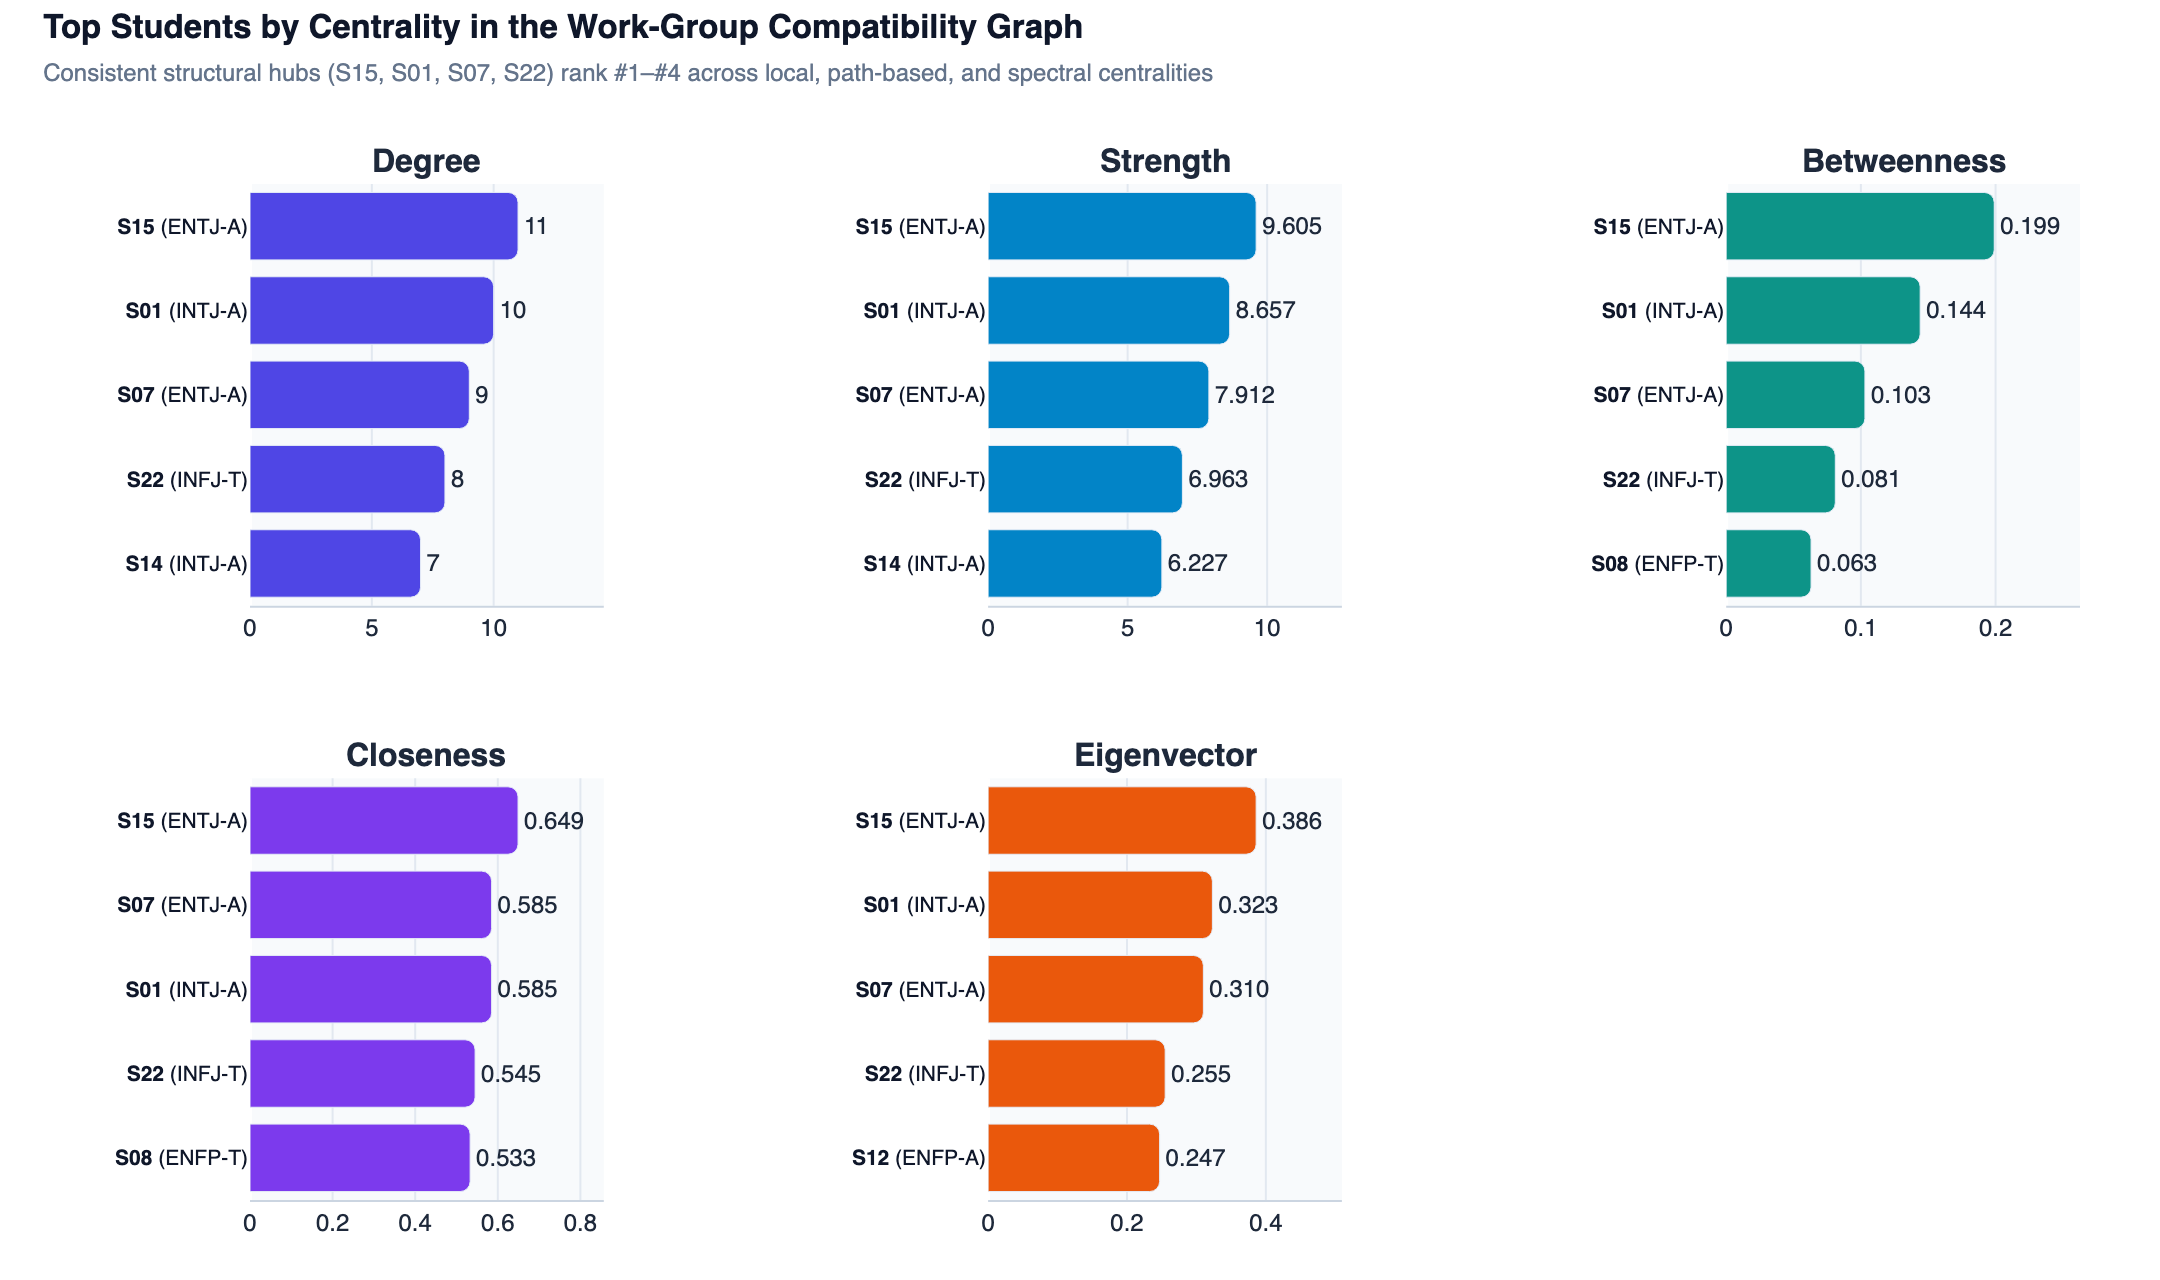

In [10]:
# Each centrality measure gets its own panel and scale; labels include MBTI type.
centrality_measures = ["Degree", "Strength", "Betweenness", "Closeness", "Eigenvector"]
measure_colors = ["#4F46E5", "#0284C7", "#0D9488", "#7C3AED", "#EA580C"]

fig_cent = make_subplots(
    rows=2,
    cols=3,
    subplot_titles=[f"<b>{m}</b>" for m in centrality_measures] + [""],
    horizontal_spacing=0.21,
    vertical_spacing=0.17,
)
for idx, (measure, mcol) in enumerate(zip(centrality_measures, measure_colors)):
    r_idx, c_idx = divmod(idx, 3)
    top_students = compatibility_centrality.nlargest(5, measure).sort_values(measure)
    labels = [f"<b>{row.Student}</b> ({row.MBTI})" for row in top_students.itertuples()]
    fmt_str = "{:.0f}" if measure == "Degree" else "{:.3f}"
    fig_cent.add_trace(
        go.Bar(
            x=top_students[measure],
            y=labels,
            orientation="h",
            marker=dict(color=mcol, cornerradius=5),
            text=[fmt_str.format(v) for v in top_students[measure]],
            textposition="outside",
            showlegend=False,
        ),
        row=r_idx + 1,
        col=c_idx + 1,
    )
    fig_cent.update_xaxes(
        range=[0, float(top_students[measure].max()) * 1.32],
        gridcolor="#E2E8F0",
        linecolor="#CBD5E1",
        row=r_idx + 1,
        col=c_idx + 1,
    )
    fig_cent.update_yaxes(tickfont=dict(size=10.5, color="#0F172A"), row=r_idx + 1, col=c_idx + 1)

fig_cent.update_layout(
    title=dict(
        text="<b>Top Students by Centrality in the Work-Group Compatibility Graph</b><br><span style='font-size:12px;color:#64748B;font-weight:400'>Consistent structural hubs (S15, S01, S07, S22) rank #1–#4 across local, path-based, and spectral centralities</span>",
        x=0.02,
        y=0.97,
        font=dict(size=16.5, color="#0F172A", family="Inter, -apple-system, sans-serif"),
    ),
    width=1080,
    height=640,
    paper_bgcolor="#FFFFFF",
    plot_bgcolor="#F8FAFC",
    font=dict(family="Inter, -apple-system, sans-serif", color="#1E293B"),
    margin=dict(l=125, r=40, t=92, b=40),
)
fig_cent.show()

## 7. Community Structure (Louvain)

We detect student clusters with weighted **Louvain modularity optimization** (`seed=42`), and check robustness against Greedy Modularity, Girvan–Newman, and $100$ random seeds ($k = 4$ in $88\%$ of runs).

While `G_sim` ($Q = 0.126$) and `G_contrast` ($Q = 0.117$) show weak cluster separation, `G_compat` reaches **$Q = 0.340$** and splits the cohort into **4 distinct collaboration profiles**: *Strategic Drivers* (`C1`), *Empathetic Diplomats* (`C2`), *Structured Organizers* (`C3`), and *Assertive Analysts* (`C4`).

In [11]:
from scipy.spatial import ConvexHull
from scipy.interpolate import splprep, splev

CLUSTER_PALETTE = [
    ("#EA580C", "rgba(234, 88, 12, 0.11)", "rgba(234, 88, 12, 0.45)", "C1 · Strategic Drivers"),
    ("#0D9488", "rgba(13, 148, 136, 0.11)", "rgba(13, 148, 136, 0.45)", "C2 · Empathetic Diplomats"),
    ("#0284C7", "rgba(2, 132, 199, 0.11)", "rgba(2, 132, 199, 0.45)", "C3 · Structured Organizers"),
    ("#7C3AED", "rgba(124, 58, 237, 0.11)", "rgba(124, 58, 237, 0.45)", "C4 · Assertive Analysts"),
]

modularity_comparison = []
partitions_by_model = {}

for model_name, graph in [
    ("Trait similarity", G_sim),
    ("Trait contrast", G_contrast),
    ("Work-group compatibility", G_compat),
]:
    comms = sorted(
        nx.community.louvain_communities(graph, weight="weight", seed=42),
        key=lambda c: (-len(c), -float(df.loc[list(c), "N"].mean())),
    )
    partitions_by_model[model_name] = comms
    mod_q = nx.community.modularity(graph, comms, weight="weight")
    intra_edges = sum(graph.subgraph(c).number_of_edges() for c in comms)
    total_edges = graph.number_of_edges()

    modularity_comparison.append({
        "Model": model_name,
        "Communities": len(comms),
        "Cluster sizes": [len(c) for c in comms],
        "Modularity (Q)": round(mod_q, 3),
        "Intra-cluster edges (%)": round(100.0 * intra_edges / total_edges, 1) if total_edges else 0.0,
    })

modularity_df = pd.DataFrame(modularity_comparison)
display(modularity_df)

compat_communities = partitions_by_model["Work-group compatibility"]
compat_modularity = nx.community.modularity(G_compat, compat_communities, weight="weight")
node_to_community = {}
cluster_summary_rows = []

for idx, comm in enumerate(compat_communities):
    members = sorted(comm)
    label = CLUSTER_PALETTE[idx][3]
    for m in members:
        node_to_community[m] = idx

    sub = G_compat.subgraph(members)
    sub_weights = [d["weight"] for _, _, d in sub.edges(data=True)]
    means = df.loc[members, traits].mean()

    cluster_summary_rows.append({
        "Community": label,
        "Size": len(members),
        "Internal edges": sub.number_of_edges(),
        "Internal density": round(nx.density(sub), 2),
        "Mean internal tie (%)": round(100.0 * float(np.mean(sub_weights)), 1) if sub_weights else 0.0,
        "Mean E (%)": round(100.0 * float(means["E"]), 1),
        "Mean N (%)": round(100.0 * float(means["N"]), 1),
        "Mean T (%)": round(100.0 * float(means["T"]), 1),
        "Mean J (%)": round(100.0 * float(means["J"]), 1),
        "Mean A (%)": round(100.0 * float(means["A"]), 1),
        "Members (MBTI)": ", ".join(f"{m} ({df.loc[m, 'mbti']}{df.loc[m, 'variant']})" for m in members),
    })

cluster_summary_df = pd.DataFrame(cluster_summary_rows)
display(cluster_summary_df)

# Benchmark Louvain against Greedy Modularity (CNM), Girvan-Newman (k=4), and 100-seed stability
gm_comms = sorted(nx.community.greedy_modularity_communities(G_compat, weight="weight"), key=len, reverse=True)
gn_iter = nx.community.girvan_newman(G_compat)
gn_k4 = sorted([ next(gn_iter) for _ in range(3) ][-1], key=len, reverse=True)
seed_runs = [
    nx.community.louvain_communities(G_compat, weight="weight", seed=s) for s in range(100)
]
seed_qs = [nx.community.modularity(G_compat, c, weight="weight") for c in seed_runs]

algo_benchmark_df = pd.DataFrame([
    {
        "Algorithm on G_compat": "Louvain (weighted, seed=42)",
        "Clusters (k)": len(compat_communities),
        "Cluster sizes": [len(c) for c in compat_communities],
        "Weighted Modularity (Q)": round(compat_modularity, 3),
        "Notes": f"k=4 in {sum(len(c)==4 for c in seed_runs)}/100 seeds (Q in [{min(seed_qs):.3f}, {max(seed_qs):.3f}])",
    },
    {
        "Algorithm on G_compat": "Greedy Modularity (Clauset-Newman-Moore)",
        "Clusters (k)": len(gm_comms),
        "Cluster sizes": [len(c) for c in gm_comms],
        "Weighted Modularity (Q)": round(nx.community.modularity(G_compat, gm_comms, weight="weight"), 3),
        "Notes": "Deterministic agglomerative merge; over-merges C2 and C3 into n=12",
    },
    {
        "Algorithm on G_compat": "Girvan-Newman (divisive, k=4 level)",
        "Clusters (k)": len(gn_k4),
        "Cluster sizes": [len(c) for c in gn_k4],
        "Weighted Modularity (Q)": round(nx.community.modularity(G_compat, gn_k4, weight="weight"), 3),
        "Notes": "Unweighted edge-betweenness split; ignores continuous tie weights",
    },
])
display(algo_benchmark_df)

,Model,Communities,Cluster sizes,Modularity (Q),Intra-cluster edges (%)
0,Trait similarity,2,"[14, 11]",0.126,62.6
1,Trait contrast,3,"[9, 9, 7]",0.117,43.3
2,Work-group compatibility,4,"[9, 6, 6, 4]",0.340,63.0


,Community,Size,Internal edges,Internal density,Mean internal tie (%),Mean E (%),Mean N (%),Mean T (%),Mean J (%),Mean A (%),Members (MBTI)
0,C1 · Strategic Drivers,9,20,0.56,87.3,58.4,66.9,74.6,68.7,69.7,"S01 (INTJ-A), S03 (ENTJ-T), S07 (ENTJ-A), S11 ..."
1,C2 · Empathetic Diplomats,6,12,0.80,84.5,58.3,69.3,43.8,48.5,42.7,"S05 (ENFP-T), S08 (ENFP-T), S12 (ENFP-A), S15 ..."
2,C3 · Structured Organizers,6,9,0.60,85.8,41.3,43.8,54.5,70.0,38.3,"S04 (ISFJ-T), S06 (ISFP-T), S17 (ESTJ-T), S19 ..."
3,C4 · Assertive Analysts,4,5,0.83,84.9,55.5,59.2,79.0,29.8,76.0,"S02 (ENTP-A), S09 (ENTP-A), S10 (ENTP-A), S16 ..."


,Algorithm on G_compat,Clusters (k),Cluster sizes,Weighted Modularity (Q),Notes
0,"Louvain (weighted, seed=42)",4,"[9, 6, 6, 4]",0.340,"k=4 in 88/100 seeds (Q in [0.322, 0.350])"
1,Greedy Modularity (Clauset-Newman-Moore),3,"[12, 7, 6]",0.306,Deterministic agglomerative merge; over-merges...
2,"Girvan-Newman (divisive, k=4 level)",4,"[7, 7, 7, 4]",0.299,Unweighted edge-betweenness split; ignores con...


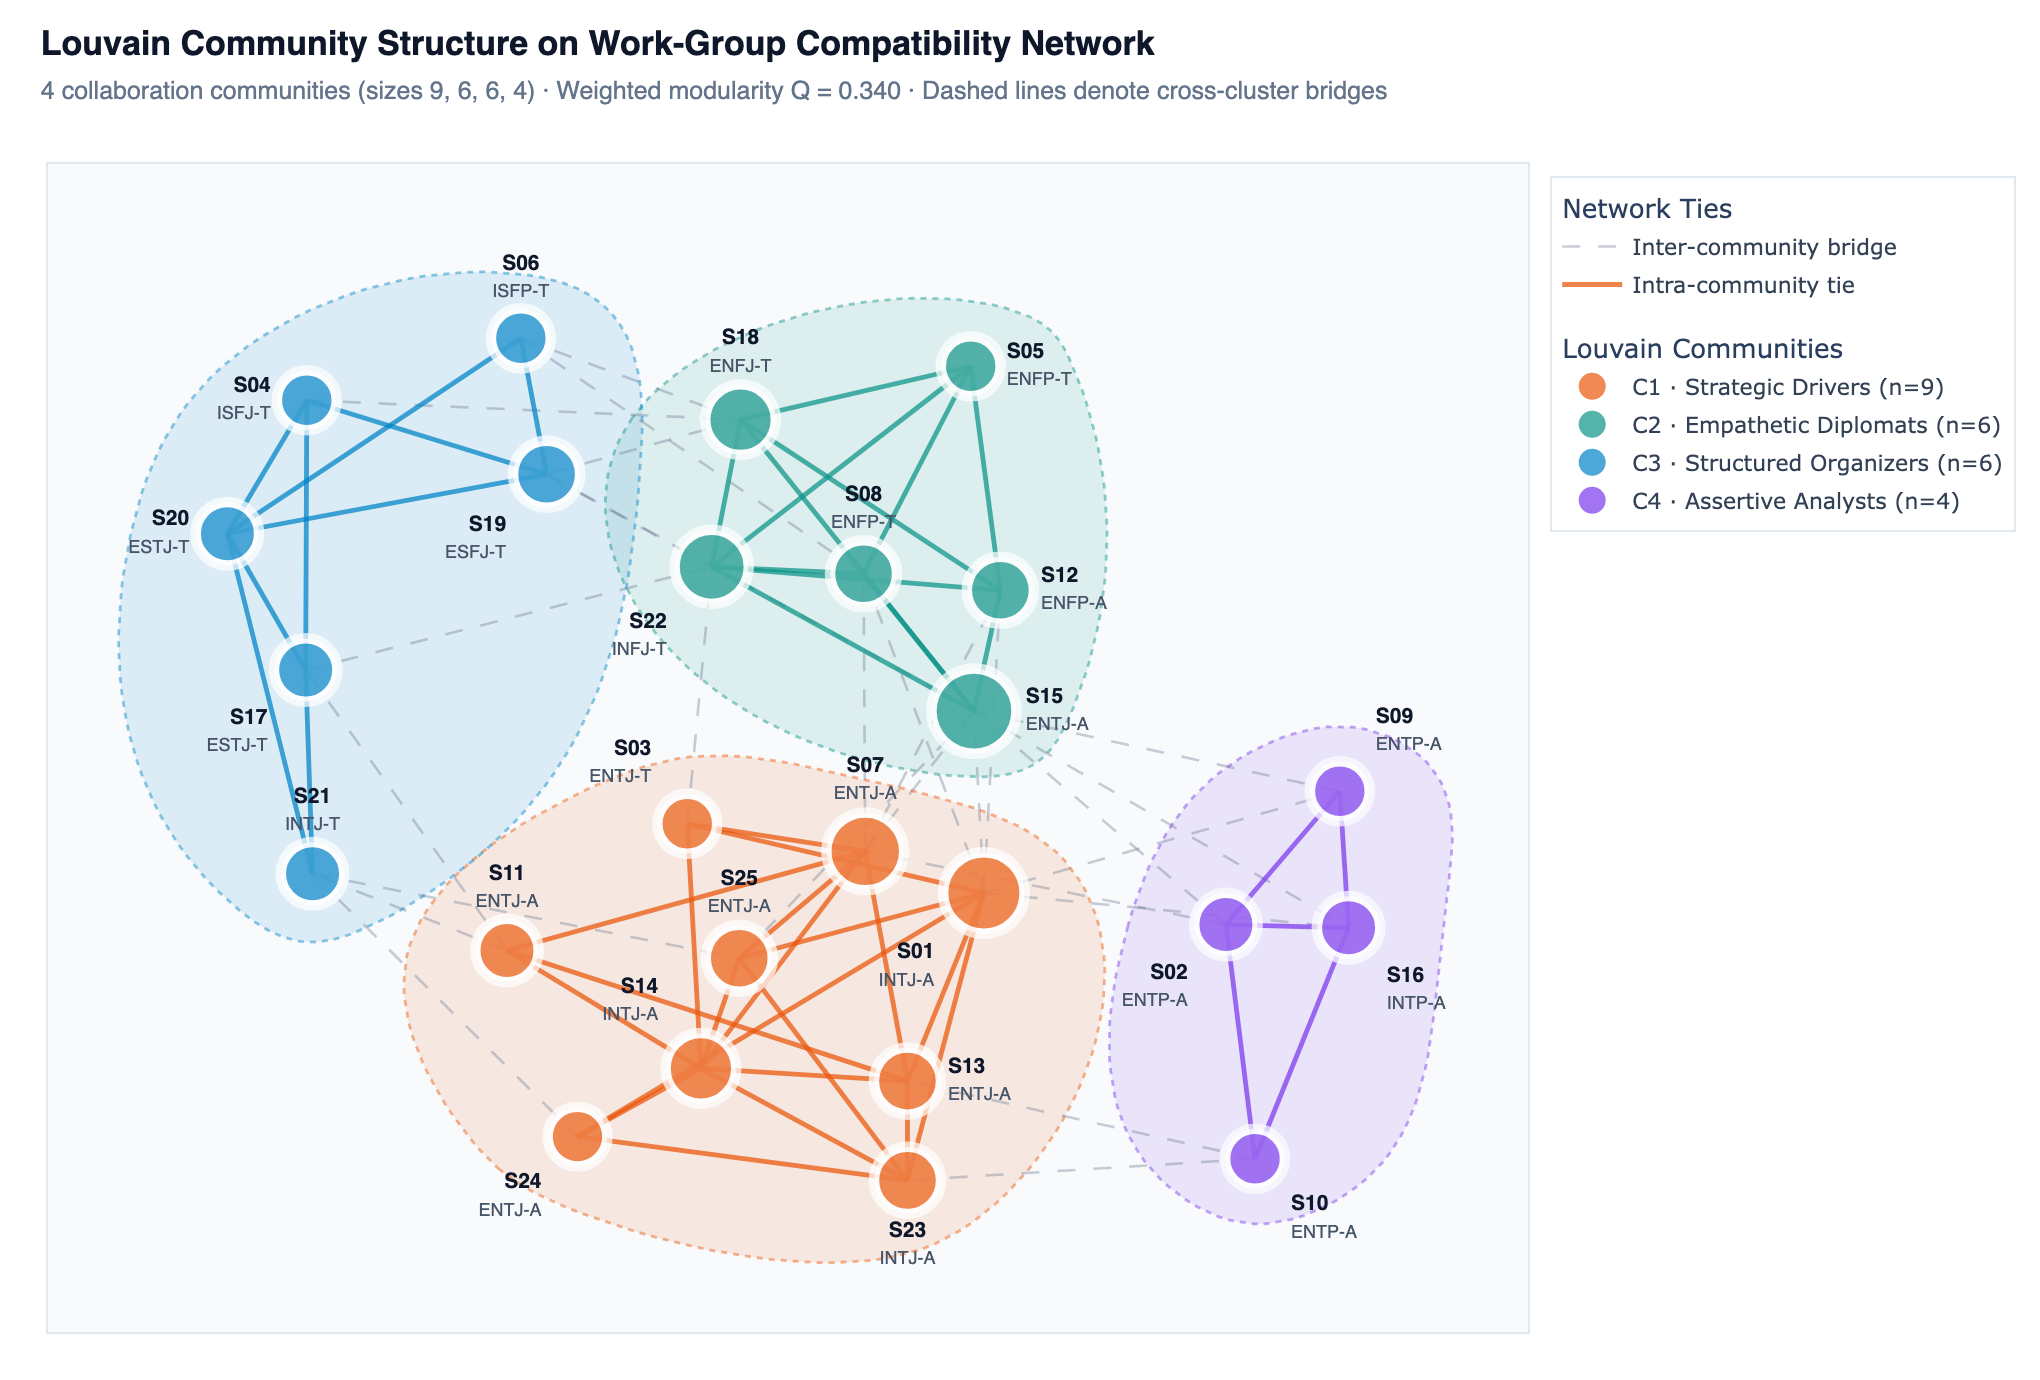

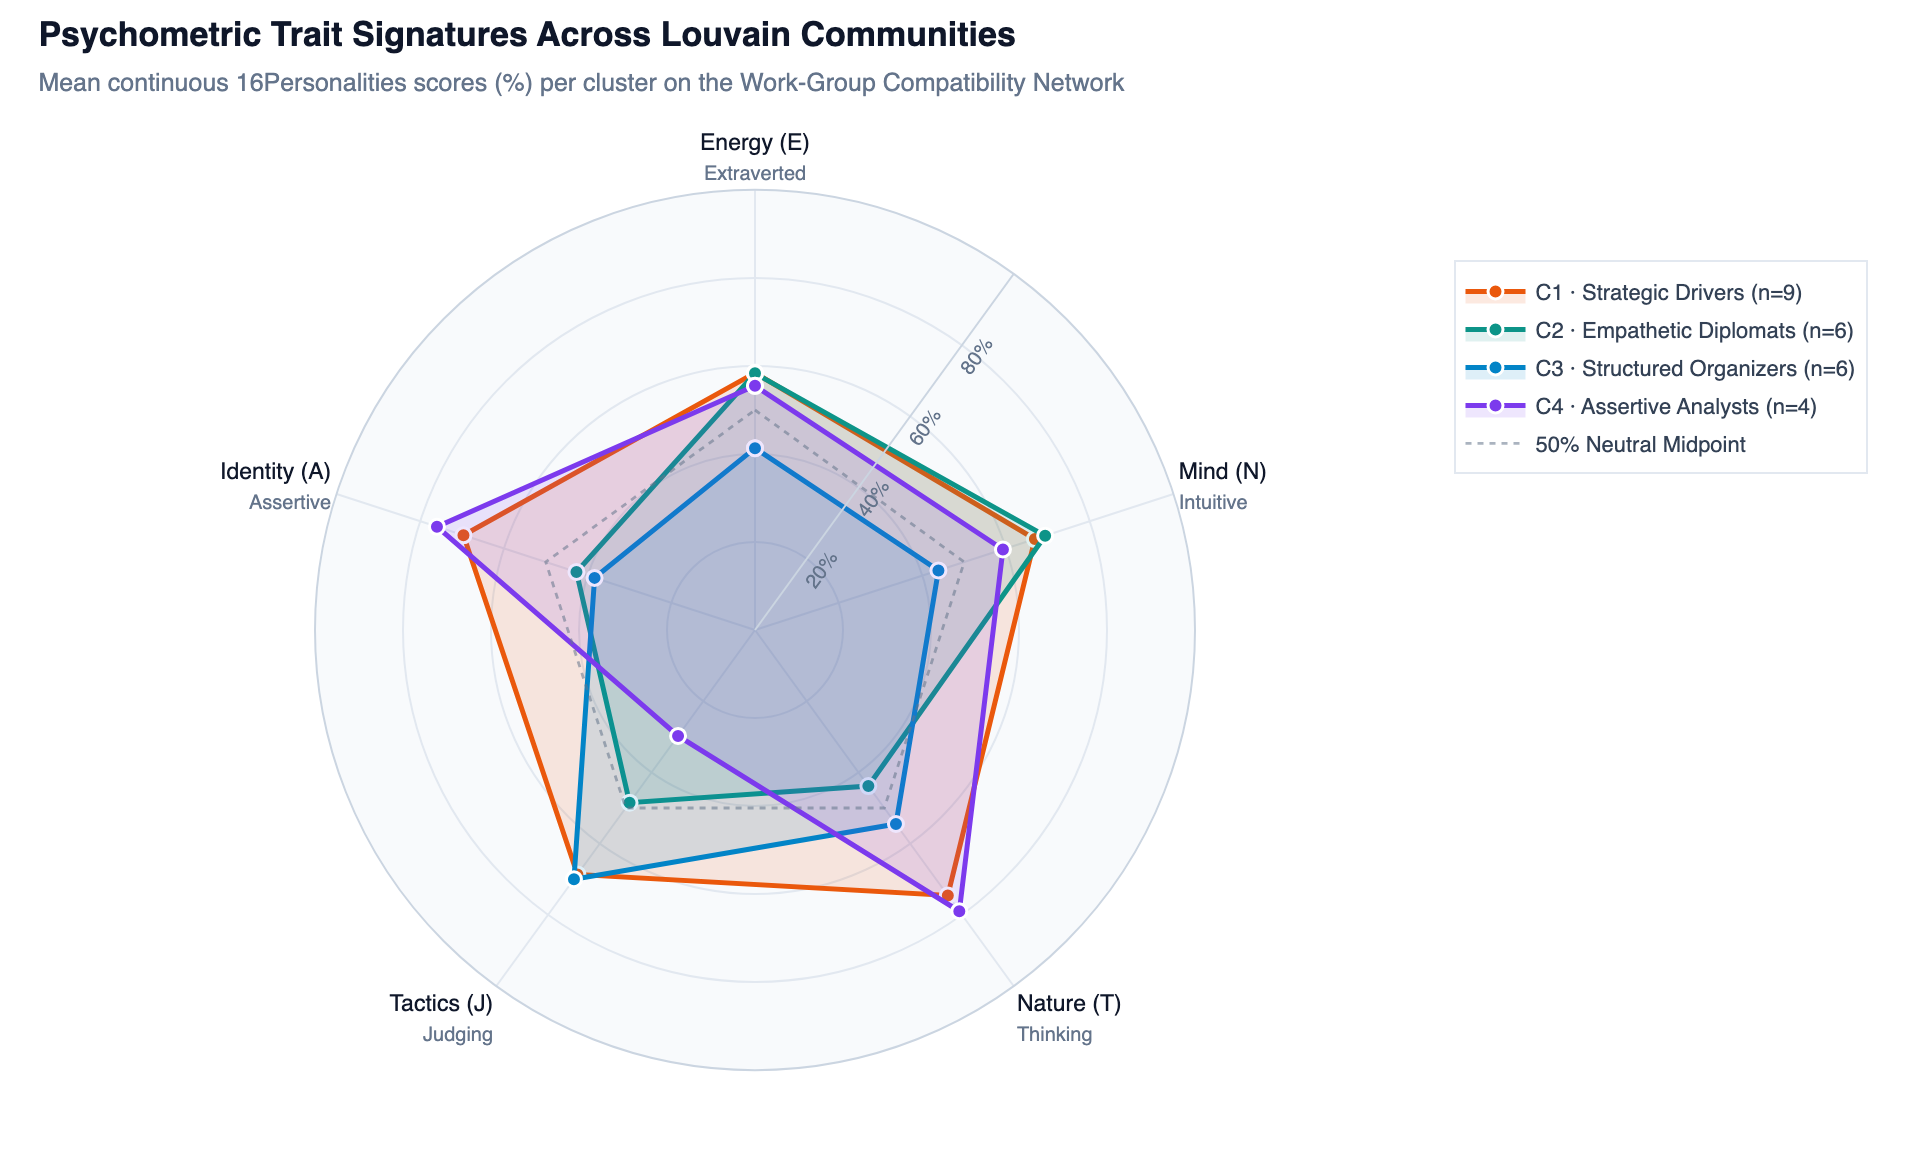

In [12]:
def smooth_hull_polygon(points, pad=0.08, n_interp=120):
    """Compute a smooth closed boundary polygon around a 2D cluster of nodes."""
    pts = np.asarray(points, dtype=float)
    centroid = pts.mean(axis=0)
    if len(pts) == 1:
        theta = np.linspace(0, 2 * np.pi, n_interp)
        return centroid[0] + pad * np.cos(theta), centroid[1] + pad * np.sin(theta)
    if len(pts) == 2:
        vec = pts[1] - pts[0]
        unit = vec / max(np.linalg.norm(vec), 1e-6)
        perp = np.array([-unit[1], unit[0]])
        pts_hull = np.array([
            pts[0] - unit * pad + perp * pad,
            pts[1] + unit * pad + perp * pad,
            pts[1] + unit * pad - perp * pad,
            pts[0] - unit * pad - perp * pad,
        ])
    else:
        angles = np.linspace(0, 2 * np.pi, 12, endpoint=False)
        expanded = np.vstack([pts + pad * np.column_stack([np.cos(a), np.sin(a)]) for a in angles])
        hull = ConvexHull(expanded)
        pts_hull = expanded[hull.vertices]

    pts_closed = np.vstack([pts_hull, pts_hull[0]])
    tck, _ = splprep([pts_closed[:, 0], pts_closed[:, 1]], s=0.002, per=True, k=min(3, len(pts_hull) - 1))
    return splev(np.linspace(0, 1, n_interp), tck)


# Figure 7A — Compatibility Network Colored by Louvain Community with Smooth Hulls
fig_comm = go.Figure()
all_nodes = list(G_compat.nodes())
all_pts = np.array([pos_compat[n] for n in all_nodes])
span = max(all_pts[:, 0].max() - all_pts[:, 0].min(), all_pts[:, 1].max() - all_pts[:, 1].min())
text_pos_compat = smart_text_positions(pos_compat, all_nodes)
strength_compat = dict(G_compat.degree(weight="weight"))

for idx, comm in enumerate(compat_communities):
    _, fill_rgba, border_rgba, _ = CLUSTER_PALETTE[idx]
    hx, hy = smooth_hull_polygon([pos_compat[n] for n in comm], pad=0.082 * span)
    fig_comm.add_trace(
        go.Scatter(
            x=hx,
            y=hy,
            fill="toself",
            fillcolor=fill_rgba,
            mode="lines",
            line=dict(color=border_rgba, width=1.4, dash="dot"),
            hoverinfo="skip",
            showlegend=False,
        )
    )

inter_x, inter_y = [], []
for u, v in G_compat.edges():
    if node_to_community[u] != node_to_community[v]:
        inter_x.extend([pos_compat[u][0], pos_compat[v][0], None])
        inter_y.extend([pos_compat[u][1], pos_compat[v][1], None])

fig_comm.add_trace(
    go.Scatter(
        x=inter_x,
        y=inter_y,
        mode="lines",
        line=dict(width=1.3, color="rgba(100, 116, 139, 0.35)", dash="dash"),
        hoverinfo="skip",
        name="Inter-community bridge",
        legendgroup="Links",
        legendgrouptitle_text="Network Ties",
    )
)

for idx, comm in enumerate(compat_communities):
    _, _, border_rgba, _ = CLUSTER_PALETTE[idx]
    intra_x, intra_y = [], []
    for u, v in G_compat.subgraph(comm).edges():
        intra_x.extend([pos_compat[u][0], pos_compat[v][0], None])
        intra_y.extend([pos_compat[u][1], pos_compat[v][1], None])
    fig_comm.add_trace(
        go.Scatter(
            x=intra_x,
            y=intra_y,
            mode="lines",
            line=dict(width=2.4, color=border_rgba.replace("0.45", "0.74")),
            hoverinfo="skip",
            name="Intra-community tie" if idx == 0 else None,
            showlegend=(idx == 0),
            legendgroup="Links",
        )
    )

fig_comm.add_trace(
    go.Scatter(
        x=[pos_compat[n][0] for n in all_nodes],
        y=[pos_compat[n][1] for n in all_nodes],
        mode="markers",
        marker=dict(size=[27 + 1.8 * G_compat.degree(n) for n in all_nodes], color="#FFFFFF"),
        hoverinfo="skip",
        showlegend=False,
    )
)

for idx, comm in enumerate(compat_communities):
    solid, _, _, cname = CLUSTER_PALETTE[idx]
    c_nodes = sorted(comm)
    hover_data = [
        f"<b>{n}</b> · {df.loc[n, 'mbti']}{df.loc[n, 'variant']}<br>"
        f"Community: <b>{cname}</b><br>"
        f"Degree: <b>{G_compat.degree(n)}</b> · Strength: <b>{strength_compat[n]:.2f}</b><br>"
        f"<span style='color:#64748B'>E {df.loc[n, 'E']:.0%} · N {df.loc[n, 'N']:.0%} · "
        f"T {df.loc[n, 'T']:.0%} · J {df.loc[n, 'J']:.0%} · A {df.loc[n, 'A']:.0%}</span>"
        for n in c_nodes
    ]
    fig_comm.add_trace(
        go.Scatter(
            x=[pos_compat[n][0] for n in c_nodes],
            y=[pos_compat[n][1] for n in c_nodes],
            mode="markers+text",
            name=f"{cname} (n={len(c_nodes)})",
            legendgroup="Communities",
            legendgrouptitle_text="Louvain Communities" if idx == 0 else None,
            text=[
                f"<b>{n}</b><br><span style='font-size:9px;color:#475569'>{df.loc[n, 'mbti']}{df.loc[n, 'variant']}</span>"
                for n in c_nodes
            ],
            textposition=[text_pos_compat[n] for n in c_nodes],
            textfont=dict(size=10.5, color="#0F172A", family="Inter, -apple-system, sans-serif"),
            marker=dict(
                size=[20 + 1.8 * G_compat.degree(n) for n in c_nodes],
                color=solid,
                line=dict(width=2.5, color="#FFFFFF"),
            ),
            customdata=hover_data,
            hovertemplate="%{customdata}<extra></extra>",
        )
    )

xs, ys = all_pts[:, 0], all_pts[:, 1]
x_pad = (xs.max() - xs.min()) * 0.16
y_pad = (ys.max() - ys.min()) * 0.18

fig_comm.update_layout(
    title=dict(
        text=(
            "<b>Louvain Community Structure on Work-Group Compatibility Network</b>"
            f"<br><span style='font-size:12.5px;color:#64748B;font-weight:400'>"
            f"4 collaboration communities (sizes 9, 6, 6, 4) · Weighted modularity Q = {compat_modularity:.3f} · Dashed lines denote cross-cluster bridges</span>"
        ),
        x=0.02, y=0.96, xanchor="left", yanchor="top",
        font=dict(size=17, color="#0F172A", family="Inter, -apple-system, sans-serif"),
    ),
    width=1020,
    height=690,
    paper_bgcolor="#FFFFFF",
    plot_bgcolor="#F8FAFC",
    margin=dict(l=24, r=250, t=82, b=24),
    xaxis=dict(showgrid=False, zeroline=False, showticklabels=False, range=[xs.min() - x_pad, xs.max() + x_pad], linecolor="#E2E8F0", linewidth=1, mirror=True),
    yaxis=dict(showgrid=False, zeroline=False, showticklabels=False, range=[ys.min() - y_pad, ys.max() + y_pad * 1.15], linecolor="#E2E8F0", linewidth=1, mirror=True),
    legend=dict(x=1.015, y=0.99, xanchor="left", yanchor="top", bgcolor="rgba(255,255,255,0.94)", bordercolor="#E2E8F0", borderwidth=1, font=dict(size=11, color="#334155"), tracegroupgap=12),
    hoverlabel=dict(bgcolor="#FFFFFF", bordercolor="#CBD5E1", font=dict(size=12, family="Inter, -apple-system, sans-serif", color="#0F172A")),
)
fig_comm.show()

# Figure 7B — Psychometric Radar Signatures Across Communities
trait_labels = [
    "Energy (E)<br><span style='font-size:10px;color:#64748B'>Extraverted</span>",
    "Mind (N)<br><span style='font-size:10px;color:#64748B'>Intuitive</span>",
    "Nature (T)<br><span style='font-size:10px;color:#64748B'>Thinking</span>",
    "Tactics (J)<br><span style='font-size:10px;color:#64748B'>Judging</span>",
    "Identity (A)<br><span style='font-size:10px;color:#64748B'>Assertive</span>",
]

fig_radar = go.Figure()
for idx, comm in enumerate(compat_communities):
    solid, fill_rgba, _, cname = CLUSTER_PALETTE[idx]
    means = [float(df.loc[sorted(comm), t].mean() * 100.0) for t in traits]
    fig_radar.add_trace(
        go.Scatterpolar(
            r=means + [means[0]],
            theta=trait_labels + [trait_labels[0]],
            fill="toself",
            fillcolor=fill_rgba.replace("0.11", "0.13"),
            mode="lines+markers",
            name=f"{cname} (n={len(comm)})",
            line=dict(color=solid, width=2.5),
            marker=dict(size=7.5, color=solid, line=dict(width=1.5, color="#FFFFFF")),
            hovertemplate=f"<b>{cname}</b><br>%{{theta}}: <b>%{{r:.1f}}%</b><extra></extra>",
        )
    )

fig_radar.add_trace(
    go.Scatterpolar(
        r=[50, 50, 50, 50, 50, 50],
        theta=trait_labels + [trait_labels[0]],
        mode="lines",
        name="50% Neutral Midpoint",
        line=dict(color="rgba(100, 116, 139, 0.55)", width=1.4, dash="dot"),
        hoverinfo="skip",
    )
)

fig_radar.update_layout(
    title=dict(
        text=(
            "<b>Psychometric Trait Signatures Across Louvain Communities</b>"
            "<br><span style='font-size:12.5px;color:#64748B;font-weight:400'>"
            "Mean continuous 16Personalities scores (%) per cluster on the Work-Group Compatibility Network</span>"
        ),
        x=0.02, y=0.96, xanchor="left", yanchor="top",
        font=dict(size=17, color="#0F172A", family="Inter, -apple-system, sans-serif"),
    ),
    width=960,
    height=580,
    paper_bgcolor="#FFFFFF",
    font=dict(family="Inter, -apple-system, sans-serif", color="#1E293B"),
    margin=dict(l=60, r=265, t=95, b=45),
    polar=dict(
        bgcolor="#F8FAFC",
        radialaxis=dict(
            visible=True,
            range=[0, 100],
            angle=54,
            tickangle=0,
            tickvals=[20, 40, 60, 80],
            ticktext=["20%", "40%", "60%", "80%"],
            tickfont=dict(size=10, color="#64748B"),
            gridcolor="#E2E8F0",
            linecolor="#CBD5E1",
        ),
        angularaxis=dict(
            tickfont=dict(size=11.5, color="#0F172A"),
            gridcolor="#E2E8F0",
            linecolor="#CBD5E1",
            direction="clockwise",
            rotation=90,
        ),
    ),
    legend=dict(
        x=1.05, y=0.92, xanchor="left", yanchor="top",
        bgcolor="rgba(255,255,255,0.95)", bordercolor="#E2E8F0", borderwidth=1,
        font=dict(size=11, color="#334155"),
    ),
    hoverlabel=dict(bgcolor="#FFFFFF", bordercolor="#CBD5E1", font=dict(size=12, family="Inter, -apple-system, sans-serif", color="#0F172A")),
)
fig_radar.show()

## 8. Optimal Work-Pair Assignment

Finally, we form concrete project teams via **maximum-cardinality maximum-weight matching** (`nx.max_weight_matching`).

The sparse $4$-NN graph achieves the **exact same global optimum** ($10.556$ total weight, $88.0\%$ mean compatibility) as the full graph $K_{25}$. Attaching the remaining odd student (`S05`) to the best-fitting pair yields **11 dyads + 1 triad**, with $10$ out of $12$ teams staying within a single Louvain community.

In [13]:
# Compare maximum-weight matching on sparse 4-NN G_compat vs. complete graph K_25
G_complete = nx.Graph()
for i in range(len(students)):
    for j in range(i + 1, len(students)):
        G_complete.add_edge(students[i], students[j], weight=float(compat_matrix[i, j]))

matching_4nn = nx.max_weight_matching(G_compat, maxcardinality=True, weight="weight")
matching_complete = nx.max_weight_matching(G_complete, maxcardinality=True, weight="weight")

weights_4nn = [G_compat[u][v]["weight"] for u, v in matching_4nn]
weights_complete = [G_complete[u][v]["weight"] for u, v in matching_complete]

matching_benchmark_df = pd.DataFrame([
    {
        "Graph Candidate Space": "Sparse Compatibility Graph (4-NN)",
        "Available Edges": G_compat.number_of_edges(),
        "Matched Pairs": len(matching_4nn),
        "Total Compatibility Weight": round(float(sum(weights_4nn)), 3),
        "Mean Pair Compatibility (%)": round(100.0 * float(np.mean(weights_4nn)), 1),
        "Min Pair Compatibility (%)": round(100.0 * float(np.min(weights_4nn)), 1),
        "Max Pair Compatibility (%)": round(100.0 * float(np.max(weights_4nn)), 1),
    },
    {
        "Graph Candidate Space": "Complete Compatibility Graph (K_25)",
        "Available Edges": G_complete.number_of_edges(),
        "Matched Pairs": len(matching_complete),
        "Total Compatibility Weight": round(float(sum(weights_complete)), 3),
        "Mean Pair Compatibility (%)": round(100.0 * float(np.mean(weights_complete)), 1),
        "Min Pair Compatibility (%)": round(100.0 * float(np.min(weights_complete)), 1),
        "Max Pair Compatibility (%)": round(100.0 * float(np.max(weights_complete)), 1),
    },
])
display(matching_benchmark_df)

# Resolve odd cohort size (N = 25) into 11 dyads + 1 optimal triad
matched_nodes = {u for pair in matching_4nn for u in pair}
unmatched_student = sorted(set(G_compat.nodes()) - matched_nodes)[0]
u_idx = students.index(unmatched_student)

best_pair_for_triad = max(
    matching_4nn,
    key=lambda p: (
        G_compat[p[0]][p[1]]["weight"]
        + compat_matrix[u_idx, students.index(p[0])]
        + compat_matrix[u_idx, students.index(p[1])]
    ) / 3.0,
)
p0, p1 = sorted(best_pair_for_triad)
triad_members = sorted([p0, p1, unmatched_student])
triad_pairs = [
    (triad_members[0], triad_members[1]),
    (triad_members[0], triad_members[2]),
    (triad_members[1], triad_members[2]),
]
triad_mean_score = float(np.mean([compat_matrix[students.index(a), students.index(b)] for a, b in triad_pairs]))

team_rows = []
student_to_team_info = {}

sorted_dyads = sorted(
    [tuple(sorted(p)) for p in matching_4nn if tuple(sorted(p)) != (p0, p1)],
    key=lambda pair: G_compat[pair[0]][pair[1]]["weight"],
    reverse=True,
)

for rank, (u, v) in enumerate(sorted_dyads, start=1):
    w = G_compat[u][v]["weight"]
    same_comm = node_to_community[u] == node_to_community[v]
    c_label = (
        CLUSTER_PALETTE[node_to_community[u]][3].split(" · ")[0]
        if same_comm
        else f"{CLUSTER_PALETTE[node_to_community[u]][3].split(' · ')[0]} ↔ {CLUSTER_PALETTE[node_to_community[v]][3].split(' · ')[0]}"
    )
    team_name = f"Team {rank:02d} (Dyad)"
    student_to_team_info[u] = f"{team_name} with {v} ({w:.1%})"
    student_to_team_info[v] = f"{team_name} with {u} ({w:.1%})"
    team_rows.append({
        "Team": team_name,
        "Format": "Dyad (2)",
        "Members": f"{u} ({df.loc[u, 'mbti']}{df.loc[u, 'variant']}), {v} ({df.loc[v, 'mbti']}{df.loc[v, 'variant']})",
        "Cluster Alignment": f"Intra-{c_label}" if same_comm else f"Cross ({c_label})",
        "Compatibility (%)": round(100.0 * w, 1),
    })

triad_team_name = f"Team {len(sorted_dyads) + 1:02d} (Triad)"
for m in triad_members:
    others = [x for x in triad_members if x != m]
    student_to_team_info[m] = f"{triad_team_name} with {others[0]} & {others[1]} ({triad_mean_score:.1%})"

triad_comms = {node_to_community[m] for m in triad_members}
team_rows.append({
    "Team": triad_team_name,
    "Format": "Triad (3)",
    "Members": ", ".join(f"{m} ({df.loc[m, 'mbti']}{df.loc[m, 'variant']})" for m in triad_members),
    "Cluster Alignment": (
        f"Intra-{CLUSTER_PALETTE[next(iter(triad_comms))][3].split(' · ')[0]}"
        if len(triad_comms) == 1
        else "Cross-cluster"
    ),
    "Compatibility (%)": round(100.0 * triad_mean_score, 1),
})

team_assignment_df = pd.DataFrame(team_rows)
display(team_assignment_df)

,Graph Candidate Space,Available Edges,Matched Pairs,Total Compatibility Weight,Mean Pair Compatibility (%),Min Pair Compatibility (%),Max Pair Compatibility (%)
0,Sparse Compatibility Graph (4-NN),73,12,10.556,88.0,76.8,94.4
1,Complete Compatibility Graph (K_25),300,12,10.556,88.0,76.8,94.4


,Team,Format,Members,Cluster Alignment,Compatibility (%)
0,Team 01 (Dyad),Dyad (2),"S01 (INTJ-A), S25 (ENTJ-A)",Intra-C1,94.4
1,Team 02 (Dyad),Dyad (2),"S11 (ENTJ-A), S14 (INTJ-A)",Intra-C1,93.8
2,Team 03 (Dyad),Dyad (2),"S17 (ESTJ-T), S20 (ESTJ-T)",Intra-C3,90.3
3,Team 04 (Dyad),Dyad (2),"S04 (ISFJ-T), S19 (ESFJ-T)",Intra-C3,89.1
4,Team 05 (Dyad),Dyad (2),"S03 (ENTJ-T), S07 (ENTJ-A)",Intra-C1,89.1
5,Team 06 (Dyad),Dyad (2),"S13 (ENTJ-A), S23 (INTJ-A)",Intra-C1,89.0
6,Team 07 (Dyad),Dyad (2),"S09 (ENTP-A), S16 (INTP-A)",Intra-C4,88.6
7,Team 08 (Dyad),Dyad (2),"S12 (ENFP-A), S15 (ENTJ-A)",Intra-C2,88.6
8,Team 09 (Dyad),Dyad (2),"S02 (ENTP-A), S10 (ENTP-A)",Intra-C4,81.9
9,Team 10 (Dyad),Dyad (2),"S06 (ISFP-T), S08 (ENFP-T)",Cross (C3 ↔ C2),81.8


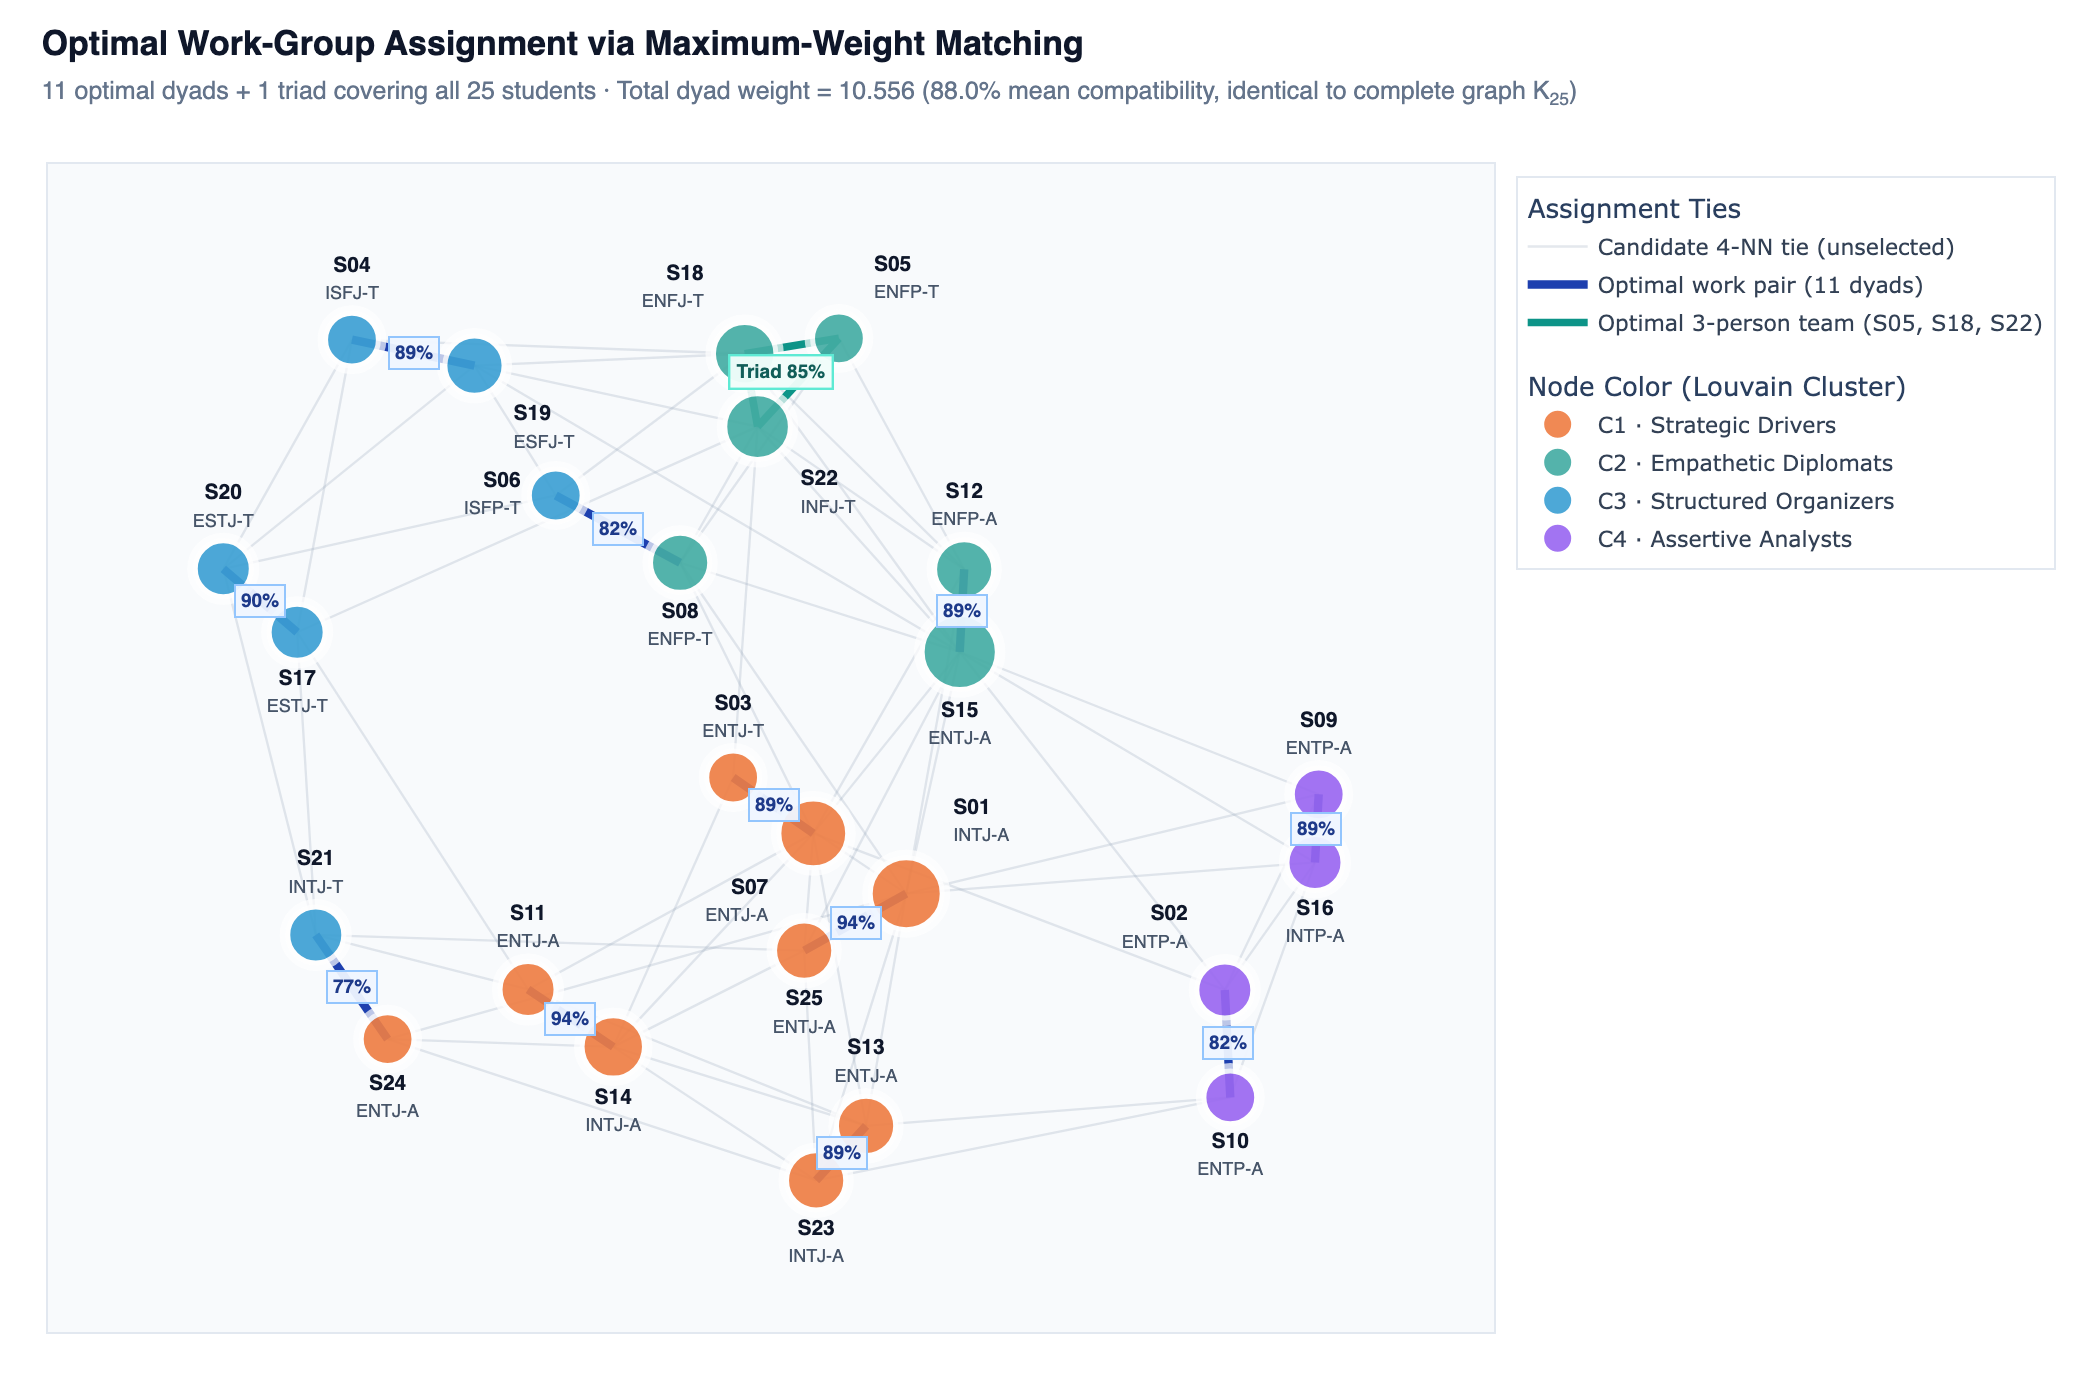

In [14]:
# Figure 8A — Optimal Work-Group Assignment Visualization
assigned_edge_set = set(sorted_dyads) | {tuple(sorted(e)) for e in triad_pairs}

G_layout = G_compat.copy()
for u, v in G_layout.edges():
    e = tuple(sorted((u, v)))
    G_layout[u][v]["lweight"] = (
        4.2 * G_compat[u][v]["weight"] if e in assigned_edge_set else 0.28 * G_compat[u][v]["weight"]
    )
for a, b in triad_pairs:
    if not G_layout.has_edge(a, b):
        G_layout.add_edge(a, b, lweight=3.8)

pos_match = nx.spring_layout(G_layout, pos=pos_compat, seed=42, k=0.82, iterations=90, weight="lweight")

dyad_x, dyad_y, mid_pts, mid_txt = [], [], [], []
for u, v in sorted_dyads:
    w = G_compat[u][v]["weight"]
    dyad_x.extend([pos_match[u][0], pos_match[v][0], None])
    dyad_y.extend([pos_match[u][1], pos_match[v][1], None])
    mid_pts.append((0.5 * (pos_match[u][0] + pos_match[v][0]), 0.5 * (pos_match[u][1] + pos_match[v][1])))
    mid_txt.append(f"<b>{w:.0%}</b>")

triad_cx = float(np.mean([pos_match[n][0] for n in triad_members]))
triad_cy = float(np.mean([pos_match[n][1] for n in triad_members]))
obstacle_pts = mid_pts + [(triad_cx, triad_cy)]

all_nodes = list(G_compat.nodes())
xs_arr = np.array([pos_match[n][0] for n in all_nodes])
ys_arr = np.array([pos_match[n][1] for n in all_nodes])
span_x = max(xs_arr.max() - xs_arr.min(), 1e-6)
span_y = max(ys_arr.max() - ys_arr.min(), 1e-6)
text_pos_match = smart_text_positions(pos_match, all_nodes, obstacles=obstacle_pts)

fig_match = go.Figure()

bg_x, bg_y = [], []
for u, v in G_compat.edges():
    if tuple(sorted((u, v))) not in assigned_edge_set:
        bg_x.extend([pos_match[u][0], pos_match[v][0], None])
        bg_y.extend([pos_match[u][1], pos_match[v][1], None])

fig_match.add_trace(
    go.Scatter(
        x=bg_x, y=bg_y, mode="lines",
        line=dict(width=1.15, color="rgba(148, 163, 184, 0.25)"),
        hoverinfo="skip", name="Candidate 4-NN tie (unselected)",
        legendgroup="Assignment", legendgrouptitle_text="Assignment Ties",
    )
)

fig_match.add_trace(
    go.Scatter(
        x=dyad_x, y=dyad_y, mode="lines",
        line=dict(width=4.2, color="#1E40AF"),
        hoverinfo="skip", name=f"Optimal work pair ({len(sorted_dyads)} dyads)",
        legendgroup="Assignment",
    )
)

trio_x, trio_y = [], []
for a, b in triad_pairs:
    trio_x.extend([pos_match[a][0], pos_match[b][0], None])
    trio_y.extend([pos_match[a][1], pos_match[b][1], None])

fig_match.add_trace(
    go.Scatter(
        x=trio_x, y=trio_y, mode="lines",
        line=dict(width=3.8, color="#0D9488"),
        hoverinfo="skip", name=f"Optimal 3-person team ({', '.join(triad_members)})",
        legendgroup="Assignment",
    )
)

fig_match.add_trace(
    go.Scatter(
        x=[pos_match[n][0] for n in all_nodes],
        y=[pos_match[n][1] for n in all_nodes],
        mode="markers",
        marker=dict(size=[27 + 1.6 * G_compat.degree(n) for n in all_nodes], color="#FFFFFF"),
        hoverinfo="skip", showlegend=False,
    )
)

for idx, comm in enumerate(compat_communities):
    solid, _, _, cname = CLUSTER_PALETTE[idx]
    c_nodes = sorted(comm)
    hover_assign = [
        f"<b>{n}</b> · {df.loc[n, 'mbti']}{df.loc[n, 'variant']}<br>"
        f"Assignment: <b>{student_to_team_info[n]}</b><br>"
        f"Community: {cname}"
        for n in c_nodes
    ]
    fig_match.add_trace(
        go.Scatter(
            x=[pos_match[n][0] for n in c_nodes],
            y=[pos_match[n][1] for n in c_nodes],
            mode="markers+text",
            name=cname,
            legendgroup="Communities",
            legendgrouptitle_text="Node Color (Louvain Cluster)" if idx == 0 else None,
            text=[
                f"<b>{n}</b><br><span style='font-size:9px;color:#475569'>{df.loc[n, 'mbti']}{df.loc[n, 'variant']}</span>"
                for n in c_nodes
            ],
            textposition=[text_pos_match[n] for n in c_nodes],
            textfont=dict(size=10.5, color="#0F172A", family="Inter, -apple-system, sans-serif"),
            marker=dict(size=[20 + 1.6 * G_compat.degree(n) for n in c_nodes], color=solid, line=dict(width=2.5, color="#FFFFFF")),
            customdata=hover_assign,
            hovertemplate="%{customdata}<extra></extra>",
        )
    )

score_annotations = [
    dict(
        x=mx, y=my, text=mtxt, showarrow=False,
        font=dict(size=9.5, color="#1E3A8A", family="Inter, -apple-system, sans-serif"),
        bgcolor="rgba(239, 246, 255, 0.95)", bordercolor="#93C5FD", borderwidth=1, borderpad=2.5,
    )
    for (mx, my), mtxt in zip(mid_pts, mid_txt)
] + [
    dict(
        x=triad_cx, y=triad_cy, text=f"<b>Triad {triad_mean_score:.0%}</b>", showarrow=False,
        font=dict(size=9.5, color="#115E59", family="Inter, -apple-system, sans-serif"),
        bgcolor="rgba(240, 253, 250, 0.96)", bordercolor="#5EEAD4", borderwidth=1.2, borderpad=3,
    )
]

x_pad, y_pad = span_x * 0.16, span_y * 0.18
fig_match.update_layout(
    title=dict(
        text=(
            "<b>Optimal Work-Group Assignment via Maximum-Weight Matching</b>"
            f"<br><span style='font-size:12.5px;color:#64748B;font-weight:400'>"
            f"{len(sorted_dyads)} optimal dyads + 1 triad covering all {len(students)} students · Total dyad weight = {sum(weights_4nn):.3f} "
            f"({100.0 * np.mean(weights_4nn):.1f}% mean compatibility, identical to complete graph K<sub>25</sub>)</span>"
        ),
        x=0.02, y=0.96, xanchor="left", yanchor="top",
        font=dict(size=17, color="#0F172A", family="Inter, -apple-system, sans-serif"),
    ),
    width=1040, height=690,
    annotations=score_annotations,
    paper_bgcolor="#FFFFFF", plot_bgcolor="#F8FAFC",
    margin=dict(l=24, r=280, t=82, b=24),
    xaxis=dict(showgrid=False, zeroline=False, showticklabels=False, range=[xs_arr.min() - x_pad, xs_arr.max() + x_pad], linecolor="#E2E8F0", linewidth=1, mirror=True),
    yaxis=dict(showgrid=False, zeroline=False, showticklabels=False, range=[ys_arr.min() - y_pad, ys_arr.max() + y_pad * 1.15], linecolor="#E2E8F0", linewidth=1, mirror=True),
    legend=dict(x=1.015, y=0.99, xanchor="left", yanchor="top", bgcolor="rgba(255,255,255,0.94)", bordercolor="#E2E8F0", borderwidth=1, font=dict(size=11, color="#334155"), tracegroupgap=12),
    hoverlabel=dict(bgcolor="#FFFFFF", bordercolor="#CBD5E1", font=dict(size=12, family="Inter, -apple-system, sans-serif", color="#0F172A")),
)
fig_match.show()

## 9. Interactive Network Explorer

Export `G_compat` to a standalone interactive HTML file (`graph.html`) with community filters and optimal team toggles.

In [15]:
from pyvis.network import Network

net = Network(
    height="100vh",
    width="100%",
    bgcolor="#F8FAFC",
    font_color="#0F172A",
    cdn_resources="in_line",
)
net.barnes_hut(gravity=-4200, central_gravity=0.28, spring_length=155, spring_strength=0.045, damping=0.22)

for node, attrs in G_compat.nodes(data=True):
    comm_idx = node_to_community[node]
    solid_color, _, _, comm_label = CLUSTER_PALETTE[comm_idx]
    tooltip = (
        f"{node} ({attrs['mbti']}{attrs['variant']})\n"
        f"Community: {comm_label}\n"
        f"Optimal Team: {student_to_team_info[node]}\n"
        f"Degree: {G_compat.degree(node)} | Strength: {strength_compat[node]:.2f}\n"
        f"E: {attrs['E']:.0%} | N: {attrs['N']:.0%} | T: {attrs['T']:.0%} | "
        f"J: {attrs['J']:.0%} | A: {attrs['A']:.0%}"
    )
    net.add_node(
        node,
        label=f"{node}\n({attrs['mbti']}{attrs['variant']})",
        title=tooltip,
        size=18 + 2.2 * G_compat.degree(node),
        shape="dot",
        color={
            "background": solid_color,
            "border": "#FFFFFF",
            "highlight": {"background": solid_color, "border": "#0F172A"},
            "hover": {"background": solid_color, "border": "#0F172A"},
        },
        borderWidth=3,
        font={"size": 13, "face": "Inter, -apple-system, BlinkMacSystemFont, sans-serif", "color": "#0F172A"},
        community=comm_idx,
    )

for u, v, attrs in G_compat.edges(data=True):
    w = attrs["weight"]
    e_key = tuple(sorted((u, v)))
    is_optimal = e_key in assigned_edge_set
    is_triad = e_key in {tuple(sorted(p)) for p in triad_pairs}
    edge_color = "#0D9488" if is_triad else ("#1E40AF" if is_optimal else "rgba(148, 163, 184, 0.42)")
    net.add_edge(
        u,
        v,
        width=4.2 if is_optimal else 1.5,
        color={"color": edge_color, "highlight": "#0F172A", "hover": "#334155"},
        title=f"{u} ↔ {v} | Compatibility: {w:.1%}" + (" (Optimal Team Tie)" if is_optimal else ""),
        optimal=is_optimal,
    )

# Add missing triad closure edge if not already in 4-NN so the triad is complete in Team View
for a, b in triad_pairs:
    if not G_compat.has_edge(a, b):
        w_ab = float(compat_matrix[students.index(a), students.index(b)])
        net.add_edge(
            a,
            b,
            width=3.6,
            dashes=True,
            color={"color": "#0D9488", "highlight": "#0F172A", "hover": "#0D9488"},
            title=f"{a} ↔ {b} | Compatibility: {w_ab:.1%} (Triad Closure Tie)",
            optimal=True,
        )

html_content = net.generate_html()

ui_overlay = f"""
<style>
  html, body {{ margin: 0; padding: 0; overflow: hidden; background: #F8FAFC; font-family: Inter, -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, sans-serif; }}
  .card {{ border: none !important; }}
  #mynetwork {{ border: none !important; height: 100vh !important; width: 100vw !important; background: #F8FAFC !important; }}
  .hud-panel {{
    position: fixed; top: 20px; left: 20px; z-index: 999; width: 310px;
    background: rgba(255, 255, 255, 0.92); backdrop-filter: blur(12px); -webkit-backdrop-filter: blur(12px);
    border: 1px solid #E2E8F0; border-radius: 14px; padding: 16px 18px;
    box-shadow: 0 10px 25px -5px rgba(15, 23, 42, 0.08);
  }}
  .hud-title {{ font-size: 15px; font-weight: 700; color: #0F172A; margin: 0 0 4px 0; letter-spacing: -0.01em; }}
  .hud-sub {{ font-size: 11.5px; color: #64748B; margin: 0 0 12px 0; line-height: 1.4; }}
  .hud-kpis {{ display: grid; grid-template-columns: repeat(3, 1fr); gap: 6px; margin-bottom: 14px; }}
  .kpi-box {{ background: #F8FAFC; border: 1px solid #E2E8F0; border-radius: 8px; padding: 6px 8px; text-align: center; }}
  .kpi-val {{ font-size: 13px; font-weight: 700; color: #0F172A; display: block; }}
  .kpi-lbl {{ font-size: 10px; color: #64748B; }}
  .hud-sec {{ font-size: 10.5px; font-weight: 600; text-transform: uppercase; letter-spacing: 0.05em; color: #475569; margin: 10px 0 6px 0; }}
  .btn-row {{ display: flex; gap: 6px; margin-bottom: 8px; }}
  .hud-btn {{
    flex: 1; padding: 6px 8px; font-size: 11.5px; font-weight: 600; border-radius: 8px; cursor: pointer;
    border: 1px solid #CBD5E1; background: #FFFFFF; color: #334155; transition: all 0.15s ease;
  }}
  .hud-btn:hover {{ background: #F1F5F9; }}
  .hud-btn.active {{ background: #0F172A; color: #FFFFFF; border-color: #0F172A; }}
  .comm-list {{ display: flex; flex-direction: column; gap: 5px; }}
  .comm-item {{
    display: flex; align-items: center; gap: 8px; font-size: 11.5px; color: #1E293B;
    padding: 5px 8px; border-radius: 7px; cursor: pointer; transition: background 0.15s ease;
  }}
  .comm-item:hover {{ background: #F1F5F9; }}
  .comm-dot {{ width: 10px; height: 10px; border-radius: 50%; flex-shrink: 0; }}
</style>
<div class="hud-panel">
  <div class="hud-title">MBTI Compatibility Network</div>
  <div class="hud-sub">5D Ideal-Partner 4-NN Graph · Albert School</div>
  <div class="hud-kpis">
    <div class="kpi-box"><span class="kpi-val">{G_compat.number_of_nodes()}</span><span class="kpi-lbl">Students</span></div>
    <div class="kpi-box"><span class="kpi-val">{compat_modularity:.3f}</span><span class="kpi-lbl">Modularity Q</span></div>
    <div class="kpi-box"><span class="kpi-val">{100.0 * np.mean(weights_4nn):.1f}%</span><span class="kpi-lbl">Mean Pair Fit</span></div>
  </div>
  <div class="hud-sec">Edge View Mode</div>
  <div class="btn-row">
    <button id="btn-all" class="hud-btn active" onclick="setEdgeMode('all')">Full 4-NN ({G_compat.number_of_edges()})</button>
    <button id="btn-opt" class="hud-btn" onclick="setEdgeMode('optimal')">Optimal Teams ({len(team_rows)})</button>
  </div>
  <div class="hud-sec">Louvain Communities (Click to Focus)</div>
  <div class="comm-list">
    <div class="comm-item" onclick="focusCommunity(null)"><span class="comm-dot" style="background:#64748B"></span><span>Show All Communities</span></div>
    <div class="comm-item" onclick="focusCommunity(0)"><span class="comm-dot" style="background:{CLUSTER_PALETTE[0][0]}"></span><span>{CLUSTER_PALETTE[0][3]} ({len(compat_communities[0])})</span></div>
    <div class="comm-item" onclick="focusCommunity(1)"><span class="comm-dot" style="background:{CLUSTER_PALETTE[1][0]}"></span><span>{CLUSTER_PALETTE[1][3]} ({len(compat_communities[1])})</span></div>
    <div class="comm-item" onclick="focusCommunity(2)"><span class="comm-dot" style="background:{CLUSTER_PALETTE[2][0]}"></span><span>{CLUSTER_PALETTE[2][3]} ({len(compat_communities[2])})</span></div>
    <div class="comm-item" onclick="focusCommunity(3)"><span class="comm-dot" style="background:{CLUSTER_PALETTE[3][0]}"></span><span>{CLUSTER_PALETTE[3][3]} ({len(compat_communities[3])})</span></div>
  </div>
</div>
<script>
  function setEdgeMode(mode) {{
    document.getElementById('btn-all').classList.toggle('active', mode === 'all');
    document.getElementById('btn-opt').classList.toggle('active', mode === 'optimal');
    const updates = [];
    edges.forEach(function(e) {{
      updates.push({{ id: e.id, hidden: (mode === 'optimal' && !e.optimal) }});
    }});
    edges.update(updates);
  }}
  function focusCommunity(cIdx) {{
    const updates = [];
    nodes.forEach(function(n) {{
      const dim = (cIdx !== null && n.community !== cIdx);
      updates.push({{
        id: n.id,
        color: dim ? {{ background: 'rgba(203, 213, 225, 0.35)', border: '#F8FAFC' }} : nodeColors[n.id],
        font: {{ color: dim ? 'rgba(15, 23, 42, 0.22)' : '#0F172A' }}
      }});
    }});
    nodes.update(updates);
  }}
</script>
"""

html_content = html_content.replace("</body>", ui_overlay + "\n</body>")
with open("graph.html", "w", encoding="utf-8") as f:
    f.write(html_content)

print("Saved redesigned interactive explorer to graph.html")

Saved redesigned interactive explorer to graph.html
